**Bitácora · Mammography NMF + PrefixSpan (fused)**

- **v1** `nb/repr_learn_mammography/Mammography_NMF_PrefixSpan_full.ipynb` (2026-10-12), ported from `nb/repr_learn_letrozole/Letrozole_NMF_PrefixSpan_full.ipynb`.
  Part A = Day 1 (bag of codes, NMF), Part B = Day 3 (ordered motifs). Cohort: `sql/mammography_cohort.sql`.
  Not ported: the letrozole teaching cells (two-patient demo, distance metrics, curse of dimensionality), the fertility / oncology weak labels, the
  letrozole-anchored matched lanes. New: breast-cancer label, filter ledger, NMF x label read-out, motif discovery by label.
- **v2 codesets** `nb/repr_learn_mammography/Mammography_NMF_PrefixSpan_v2.ipynb` (2026-10-16) <- **this notebook**
  Clone of `..._full` that runs on `codesets_v2.yaml` (USPSTF 2024 screening + ASCO 2026 surveillance guidelines, before / after in `codesets_v1_vs_v2.md`)
  with `TOKEN_LEVEL = 'group'` (a codeset tag is the NMF token). Cohort, label, filters F1-F7 and `config/robustness.yaml` are unchanged, and `mammography`,
  `breast_cancer` and `in_situ` resolve to the same concept ids as v1, so a v1 / v2 difference comes only from how features are grouped.
  Only cells 2, 6, 10, 14, 29, 30, 44, 48 and the last two differ from `..._full`. Files are labelled `v2`, so the `full` outputs are not overwritten.


# Mammography · NMF bundles and sequence motifs — guideline codesets v2

**Question.** Among patients with a mammography, does *unsupervised* pattern discovery find structure that separates breast-cancer patients from the rest?

**No explicit modelling.** No classifier is fitted and the label never enters a feature, a bundle or a motif. NMF (Part A) and PrefixSpan (Part B) are run blind;
the breast-cancer label is only used afterwards to *read* what they found (share of cancer per bundle, motifs more common in one group).

**Filters.** Every preprocessing filter is in one cell (section 1), each with its rationale, and the `LEDGER` table prints how many events and patients each one removes.

Switches in the next cell: `WINDOW_MONTHS`, `DROP_LABEL_PROXIES`, `PRE_DX_ONLY`, `DROP_INSITU_ONLY`, `K_OVERRIDE`, `CODESETS_FILE`, `TOKEN_LEVEL`.  
`TOKEN_LEVEL='concept'` keeps one NMF token per concept (as the `full` run) and only anchors / flags / loadings use v2; `'group'` makes each codeset tag the NMF token, which is the real test of v2.

In [1]:
import os, yaml

COHORT = 'mammography'
ANCHOR = 'mammography'        # codeset tag of the cohort-defining event (same concept ids in v1 and v2)

# ---- switches (each one is a documented filter in section 1) ----
WINDOW_MONTHS      = None     # int: keep events within +/- N months of ANY mammography (merged per patient). None = full history
DROP_LABEL_PROXIES = False    # True: also drop the cancer treatment / staging codes in LABEL_PROXY_TAGS (they are near-perfect proxies of the label)
PRE_DX_ONLY        = False    # True: for cancer patients keep only events strictly BEFORE their first breast-cancer diagnosis
DROP_INSITU_ONLY   = False    # True (F3): drop patients with in-situ disease (DCIS / LCIS) and no invasive-cancer criterion. False: keep them (they count as 'no breast cancer' in the label)
K_OVERRIDE         = None     # None = the k chosen by the stability sweep; set an int to force it (9 = the k of the `full` run)
CODESETS_FILE      = 'codesets_v2.yaml'   # 'codesets.yaml' = v1, the file of the `full` run (then take 'breast_absence' out of LABEL_PROXY_TAGS)
TOKEN_LEVEL        = 'group'              # 'group': a codeset tag is the NMF token (curated concepts collapse) | 'concept': one token per concept (as `full`)
assert TOKEN_LEVEL in ('group', 'concept'), TOKEN_LEVEL

# Codesets whose presence is (almost only) a consequence of a breast-cancer diagnosis. They are NOT removed by default: the discovery is
# allowed to find "mastectomy -> chemotherapy -> endocrine therapy". Motifs and bundles containing them are flagged `has_proxy` so the
# trivial findings can be told apart from the rest. breast_reconstruction is excluded from the list: it is often elective.
# antineoplastic_drug is an umbrella: it still groups cdk46_inhibitor and her2_targeted (v2 tags), so those are flagged too.
LABEL_PROXY_TAGS = ['in_situ', 'lumpectomy', 'mastectomy', 'lymph_node_procedure', 'chemotherapy', 'antineoplastic_drug',
                    'endocrine_therapy', 'radiation_therapy', 'receptor_assay', 'metastasis',
                    'breast_absence']      # v2: state after mastectomy

# `v2` / `v1` + `_concept` when the tokens are per concept + the usual switches: no file of the `full` run is overwritten
CS_LABEL = os.path.splitext(CODESETS_FILE)[0].replace('codesets', '').lstrip('_') or 'v1'
VARIANT = (CS_LABEL + ('' if TOKEN_LEVEL == 'group' else '_concept') + (f'_win{WINDOW_MONTHS}' if WINDOW_MONTHS else '')
           + ('_noproxy' if DROP_LABEL_PROXIES else '') + ('_predx' if PRE_DX_ONLY else '') + ('_dropinsitu' if DROP_INSITU_ONLY else ''))
TAG     = f"{COHORT}_{VARIANT}"      # used in every cache / json / xlsx file name

CFG     = yaml.safe_load(open('config/robustness.yaml'))
OUT_DIR = CFG['paths']['extract_dir']
RES_DIR = CFG['paths']['out_dir']
os.makedirs(RES_DIR, exist_ok=True)
print('variant:', VARIANT, '|', CODESETS_FILE, '|', TOKEN_LEVEL, 'tokens')


variant: v2 | codesets_v2.yaml | group tokens


# Part A · Day 1 — NMF bundles

## 0 · Getting the data

`eo.extract_cohort()` dumps every table of the cohort in `sql/mammography_cohort.sql` to CSV (`ethos_dip` excluded at the source), so the rest of the notebook runs offline.
The cell skips the pull when `OUT_DIR` exists; delete the folder to re-pull.

**`master_observation` is not extracted and `Observation` is never loaded.** OMOP observation rows are documentation-style concepts (for example
"Mammogram assessment category of benign, documented", "Family history of ...") that add noise, not clinical pattern.
The cohort SQL still adds patients whose only mammography hit is an Observation row; such patients have no mammography event here and are counted in section 1.

Parquet: `eo._read` prefers `<table>.parquet` next to each CSV when it is not older than the CSV (about 20x smaller, loads only the columns asked for). Build or rebuild the files with `python csv_to_parquet.py` after every re-extract; without them the CSVs are read as before.

In [2]:
import math, time, json, hashlib, itertools, collections, re
import numpy as np, pandas as pd, scipy.sparse as sp, matplotlib.pyplot as plt
import ethos_omop as eo
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 120)

# Observation is skipped at the source (see above); the other master_* tables, person and death are dumped as usual
EXTRACT_TABLES = [t for t in eo.CORE_TABLES if t != 'master_observation']
if not os.path.isdir(OUT_DIR):
    eo.extract_cohort(CFG['paths']['cohort_sql'], out_dir=OUT_DIR, tables=EXTRACT_TABLES)
else:
    print(f"{OUT_DIR} already populated -- skipping extract_cohort(). Delete it to re-pull from Snowflake.")
print(eo.describe_extract(OUT_DIR).to_string(index=False))

../../inputs/mammography_cohort/ already populated -- skipping extract_cohort(). Delete it to re-pull from Snowflake.
                           file     rows     MB
    master_visit_occurrence.csv 21632768 2702.9
master_condition_occurrence.csv 18166560 2657.3
master_procedure_occurrence.csv 13096558 1942.4
       master_drug_exposure.csv 10645846 2060.5
         master_measurement.csv  8786784 1190.9
           concept_ancestor.csv  1040961   22.5
                     person.csv   145170   19.1
                    concept.csv    26502    3.4
                      death.csv       16    0.0


In [3]:
# Load everything into one long table of events (visit / condition / procedure / drug / measurement) for every patient in the cohort.
# load_events() already keeps standard concepts only, drops concept_id = 0 (unmapped) and rows without a date.
# Claims carry a DATE, not a timestamp: same-day events have no true order, eo.DOMAIN_ORDER breaks ties deterministically (arbitrary, written down).
DOMAINS = ['Visit', 'Condition', 'Drug', 'Procedure', 'Measurement']    # no 'Observation': noise, see section 0

concept  = eo.load_concept(OUT_DIR)
codesets = eo.build_codesets(concept, codesets=eo._load_codesets(CODESETS_FILE), verbose=False)   # explicit: eo.CODESETS stays the v1 file
_need    = set(LABEL_PROXY_TAGS) | {ANCHOR, 'breast_cancer', 'in_situ', 'mammography_screening', 'mammography_diagnostic'}
assert _need <= set(codesets), f"{CODESETS_FILE} lacks tags this notebook reads: {sorted(_need - set(codesets))}"
raw      = eo.load_events(OUT_DIR, domains=DOMAINS)
person   = eo.load_person(OUT_DIR)
cname    = concept.drop_duplicates('concept_id').set_index('concept_id')['concept_name']
print(f"{raw.shape[0]:,} raw events, {raw.person_id.nunique():,} patients with events, {len(person):,} patients in the cohort")
print(person.gender.value_counts().to_string())

66,107,290 raw events, 145,170 patients with events, 145,170 patients in the cohort
gender
female    142583
male        2587


## 1 · The label, the filters and the ledger

### The breast-cancer label

A patient is a **case** when any condition row meets one of these criteria; everyone else is a control. The extract keeps standard concepts only, so ICD codes are not in
`concept.csv`; they are read from the raw `condition_source_value` column. This extends the letrozole notebook's rule (ICD-9 174.x, ICD-10 C50.x, SNOMED 4162253) with
**personal history** (ICD-10 Z85.3, ICD-9 V10.3) and ICD-9 175.x (male breast): in a mammography cohort many survivors carry only a history code, and calling them
"no cancer" would put cancer patients in the control group.

**Leakage.** The concepts behind the label (every standard concept of a matching row, plus the name-matched `breast_cancer` codeset) are removed from the features in the filter cell below.

In [4]:
cond = eo._read(OUT_DIR, 'master_condition_occurrence',                  # parquet when built (csv_to_parquet.py), else the CSV
                columns=['person_id', 'condition_concept_id', 'condition_source_value', 'condition_start_date'],
                dtype={'condition_source_value': str})
cond['condition_start_date'] = pd.to_datetime(cond['condition_start_date'])
src  = cond.condition_source_value.fillna('').str.upper().str.replace('.', '', regex=False)       # 'C50.911' -> 'C50911'

# Source-code matches are anchored: a bare startswith('174') would also match SNOMED / CPT codes that merely begin with 174.
CRIT = {'ICD-10 C50.x':                          src.str.startswith('C50'),
        'ICD-9 174.x / 175.x':                   src.str.fullmatch(r'17[45]\d{0,2}'),
        'SNOMED 4162253':                        cond.condition_concept_id.eq(4162253),
        'personal history (ICD-10 Z85.3 / ICD-9 V10.3)': src.str.fullmatch(r'Z853|V103\d?')}
case_mask  = np.logical_or.reduce(list(CRIT.values()))
case_rows  = cond[case_mask]
case_ids   = set(case_rows.person_id)                                       # label = 1
first_dx   = case_rows.groupby('person_id').condition_start_date.min()      # first matching row per case (for PRE_DX_ONLY and Table 1)
crit_ids   = {k: set(cond.person_id[m]) for k, m in CRIT.items()}

# concepts that ARE the label: every standard concept of a matching row, plus the name-matched codeset
LABEL_CONCEPTS = (set(case_rows.condition_concept_id.dropna().astype('int64')) | set(codesets['breast_cancer'])) - {0}

# in-situ disease only (DCIS / LCIS, ICD-10 D05.x, ICD-9 233.0) is neither cancer nor clearly "no cancer": kept by default (DROP_INSITU_ONLY = False), dropped by F3 when it is True
in_situ_rows = src.str.fullmatch(r'D05\w*|2330') | cond.condition_concept_id.isin(codesets['in_situ'])
in_situ_only = set(cond.person_id[in_situ_rows]) - case_ids

cohort_ids = set(person.person_id)
print(f"cases {len(case_ids & cohort_ids):,} of {len(cohort_ids):,} patients ({len(case_ids & cohort_ids) / len(cohort_ids):.1%});  in-situ only: {len(in_situ_only):,}")
display(pd.DataFrame({k: {'patients': len(v & cohort_ids)} for k, v in crit_ids.items()}).T)
lc = (cond[cond.condition_concept_id.isin(LABEL_CONCEPTS)].condition_concept_id.value_counts().rename('events').to_frame()
        .assign(concept=lambda d: d.index.map(cname.get)))
print(f"{len(LABEL_CONCEPTS)} label concepts will be removed from the features. Most frequent:")
display(lc.head(15))
assert 0 < len(case_ids & cohort_ids) < len(cohort_ids), "label is constant: check CRIT against the extract"

cases 985 of 145,170 patients (0.7%);  in-situ only: 207


,patients
ICD-10 C50.x,985
ICD-9 174.x / 175.x,0
SNOMED 4162253,795
personal history (ICD-10 Z85.3 / ICD-9 V10.3),0


13 label concepts will be removed from the features. Most frequent:


,events,concept
condition_concept_id,,
4162253,7352,Primary malignant neoplasm of breast
4187850,5474,Primary malignant neoplasm of upper outer quadrant of breast
4092513,2072,Malignant neoplasm of overlapping sites of breast
4158563,1807,Primary malignant neoplasm of upper inner quadrant of breast
4187851,1228,Primary malignant neoplasm of lower inner quadrant of breast
1075588,1003,Primary malignant neoplasm of central portion of breast
4188545,859,Primary malignant neoplasm of lower outer quadrant of breast
1075508,444,Malignant neoplasm of nipple and areola
1075605,106,Primary malignant neoplasm of axillary tail of right breast


### The filters

| # | Filter | Rationale |
|---|---|---|
| F0 | `load_events()`: standard concepts only, `concept_id != 0`, rows without a date dropped, no Observation domain | non-standard / unmapped codes double-count or carry no meaning; Observation is noise (section 0) |
| F1 | drop every visit event | pharmacy / office / ED visits are the most frequent tokens and group patients by care setting, not by condition (letrozole v2) |
| F2 | drop every concept that defines the label | otherwise the "cancer bundle" is the diagnosis code itself |
| F3 | *(off by default, `DROP_INSITU_ONLY`)* drop patients with in-situ disease only | DCIS / LCIS is not invasive disease and not "no cancer": ambiguous label. Off: they stay, count as "no breast cancer" in the label, and carry some risk, so they need manual review |
| F4 | *(off by default)* drop the cancer treatment / staging codes `LABEL_PROXY_TAGS` | they are consequences of the diagnosis; dropping them asks what separates the groups *without* treatment |
| F5 | *(off by default)* cases: keep events strictly before the first diagnosis | the pre-diagnosis picture only. Confound: controls keep their whole history, so history length differs by group |
| F6 | *(off by default)* keep events within +/- `WINDOW_MONTHS` of any mammography | care around the screening, not the whole life |
| F7 | codes (not patients) below the prevalence floor, or present in >= 99% of patients, are dropped from the matrix and the sequences | a code in a handful of patients cannot form a pattern; a code in everyone is a constant column that only eats a component (section 2) |
| F8 | keep female patients only (applied with the patient filters F1-F3, before tagging) | screening mammography is a program for women and breast cancer in men is rare, so sex would otherwise be a feature |

Nothing else is filtered: no minimum history (reported in the tables). Patients with no mammography event in the loaded domains stay in the full variant and are counted below.

In [5]:
LEDGER = []
def log_filter(step, rule, why, before=None, after=None, applied=True):
    LEDGER.append({'step': step, 'applied': applied, 'rule': rule, 'rationale': why,
                   'events': f"{len(before):,} -> {len(after):,}" if applied else '',
                   'patients': f"{before.person_id.nunique():,} -> {after.person_id.nunique():,}" if applied else ''})

ev = raw
# F1: visits
is_visit = ev['domain'].astype(str).str.lower().eq('visit') | ev['vocabulary_id'].astype(str).str.lower().eq('visit')
nxt = ev[~is_visit]
log_filter('F1', "drop rows whose domain or vocabulary is 'visit'", 'visits group patients by care setting, not by condition', ev, nxt); ev = nxt

# F2: label-defining concepts (leakage)
nxt = ev[~ev.concept_id.isin(LABEL_CONCEPTS)]
log_filter('F2', f'drop {len(LABEL_CONCEPTS)} concepts that define the breast-cancer label', 'the label must not be a feature', ev, nxt); ev = nxt

# F3: in-situ-only patients (optional)
if DROP_INSITU_ONLY:
    nxt = ev[~ev.person_id.isin(in_situ_only)]
    log_filter('F3', 'drop patients with in-situ breast disease but no invasive-cancer criterion', 'ambiguous label: neither case nor control', ev, nxt); ev = nxt
else:
    log_filter('F3', 'drop patients with in-situ breast disease but no invasive-cancer criterion', f'off: {len(in_situ_only):,} in-situ-only patients kept, labelled no breast cancer', applied=False)

# F8: female patients only (person.gender = gender_source_value; any other value, including missing, is dropped)
female = set(person.loc[person.gender.astype(str).str.upper().eq('FEMALE'), 'person_id'])
nxt = ev[ev.person_id.isin(female)]
log_filter('F8', 'keep female patients only (person gender = FEMALE)', 'screening mammography is a program for women and breast cancer in men is rare: sex would otherwise be a feature', ev, nxt); ev = nxt

events = eo.tag_events(ev.reset_index(drop=True), codesets, token_level=TOKEN_LEVEL, multi_group=True)
del raw, ev, nxt

# F4: label proxies (optional)
if DROP_LABEL_PROXIES:
    nxt = events[~eo.group_mask(events, LABEL_PROXY_TAGS)]
    log_filter('F4', f'drop codesets {LABEL_PROXY_TAGS}', 'consequences of the diagnosis, near-perfect proxies of the label', events, nxt); events = nxt
else:
    log_filter('F4', f'drop codesets {LABEL_PROXY_TAGS}', 'off: kept and flagged has_proxy', applied=False)

# F5: cases cut at their first diagnosis (optional)
if PRE_DX_ONLY:
    dx = events.person_id.map(first_dx)
    nxt = events[dx.isna() | (events.event_date < dx)]
    log_filter('F5', 'cases: keep events strictly before the first breast-cancer diagnosis row', 'pre-diagnosis picture; controls keep all history (length confound)', events, nxt); events = nxt
else:
    log_filter('F5', 'cases: keep events strictly before the first diagnosis', 'off: full history', applied=False)

# F6: window around any mammography (optional)
if WINDOW_MONTHS:
    nxt = eo.window_around_anchor(events, ANCHOR, months=WINDOW_MONTHS)
    log_filter('F6', f'keep events within +/- {WINDOW_MONTHS} months of any {ANCHOR} event', 'care around the screening; patients with no mammography event are dropped', events, nxt); events = nxt
else:
    log_filter('F6', 'window around mammography', 'off: full history', applied=False)

events = events.reset_index(drop=True)
display(pd.DataFrame(LEDGER).set_index('step'))

# patient-level facts used all over the notebook
pids_ev  = np.sort(events.person_id.unique())
is_case  = pd.Series([p in case_ids for p in pids_ev], index=pids_ev)
anc_pat  = set(events.loc[eo.group_mask(events, ANCHOR), 'person_id'])
print(f"events {events.shape}, patients {len(pids_ev):,} (cases {int(is_case.sum()):,}, controls {int((~is_case).sum()):,})")
print(f"codeset coverage: {events.in_codeset.mean():.1%} of events carry a clinical tag")
print(f"patients with >= 1 {ANCHOR} event: {len(anc_pat):,} of {len(pids_ev):,}; without: {len(pids_ev) - len(anc_pat):,} "
      f"(mammography only in a domain not loaded, or removed by F5 / F6)")
print(f"female patients of the cohort with no event left: {len(cohort_ids & female) - len(pids_ev):,}")

,applied,rule,rationale,events,patients
step,,,,,
F1,True,drop rows whose domain or vocabulary is 'visit',"visits group patients by care setting, not by condition","66,107,290 -> 50,514,305","145,170 -> 145,170"
F2,True,drop 13 concepts that define the breast-cancer label,the label must not be a feature,"50,514,305 -> 50,493,881","145,170 -> 145,170"
F3,False,drop patients with in-situ breast disease but no invasive-cancer criterion,"off: 207 in-situ-only patients kept, labelled no breast cancer",,
F8,True,keep female patients only (person gender = FEMALE),screening mammography is a program for women and breast cancer in men is rare: sex would otherwise be a feature,"50,493,881 -> 49,595,708","145,170 -> 142,583"
F4,False,"drop codesets ['in_situ', 'lumpectomy', 'mastectomy', 'lymph_node_procedure', 'chemotherapy', 'antineoplastic_drug',...",off: kept and flagged has_proxy,,
F5,False,cases: keep events strictly before the first diagnosis,off: full history,,
F6,False,window around mammography,off: full history,,


events (49595708, 13), patients 142,583 (cases 962, controls 141,621)
codeset coverage: 8.1% of events carry a clinical tag
patients with >= 1 mammography event: 142,548 of 142,583; without: 35 (mammography only in a domain not loaded, or removed by F5 / F6)
female patients of the cohort with no event left: 0


In [6]:
# Codeset check: read what the key tags actually matched (a broken regex resolves to a small NONZERO number of concepts).
for tag in dict.fromkeys(['mammography', 'breast_cancer', 'in_situ'] + LABEL_PROXY_TAGS):
    ids = sorted(codesets[tag])
    print(f"\n--- {tag} ({len(ids)} concepts, {events.loc[eo.group_mask(events, tag), 'person_id'].nunique():,} patients after filters) ---")
    print('\n'.join('   ' + str(cname.get(i))[:110] for i in ids[:8]) + ('\n   ...' if len(ids) > 8 else ''))
tag_n = pd.DataFrame({'concepts': {t: len(i) for t, i in codesets.items()},
                      'patients': {t: events.loc[eo.group_mask(events, t), 'person_id'].nunique() for t in codesets}})
display(tag_n.assign(prevalence=lambda d: (d.patients / len(pids_ev)).map('{:.1%}'.format)).T)


--- mammography (7 concepts, 142,548 patients after filters) ---
   Diagnostic mammography, including computer-aided detection (cad) when performed; unilateral (Deprecated)
   Screening mammography
   Mammography of bilateral breasts
   Screening mammography of bilateral breasts
   Diagnostic mammography, including computer-aided detection (CAD) when performed; unilateral
   Screening mammography, bilateral (2-view study of each breast), including computer-aided detection (CAD) when 
   Diagnostic mammography, including computer-aided detection (CAD) when performed; bilateral

--- breast_cancer (12 concepts, 0 patients after filters) ---
   Primary malignant neoplasm of axillary tail of breast
   Primary malignant neoplasm of central portion of breast
   Primary inflammatory carcinoma of breast
   Primary malignant neoplasm of axillary tail of left breast
   Primary malignant neoplasm of axillary tail of right breast
   Malignant neoplasm of overlapping sites of breast
   Primary mali

,mammography_screening,mammography_diagnostic,mammography,breast_tomosynthesis,breast_ultrasound,breast_mri,breast_exam,breast_density,mammographic_finding,breast_symptom,benign_breast_disease,breast_uncertain_neoplasm,breast_cyst_procedure,breast_biopsy,breast_localization,brca_testing,germline_susceptibility,genetic_counseling,radiation_therapy,hormonal_contraceptive,...,receptor_assay,in_situ,breast_cancer,lumpectomy,mastectomy,breast_absence,lymph_node_procedure,chemotherapy,cdk46_inhibitor,her2_targeted,antineoplastic_drug,endocrine_therapy,metastasis,breast_reconstruction,tumor_marker,cbc,chemistry_panel,bone_scan_pet,cervical_screening,colorectal_screening
concepts,3,3,7,4,2,9,1,1,4,15,13,3,3,8,8,21,3,1,44,23,...,13,7,12,5,3,2,6,15,7,10,30,9,1,10,3,5,3,10,40,24
patients,130398,47532,142548,133602,47789,4705,3157,2114,12582,19692,9328,321,1256,7558,1014,2302,59,1029,370,8507,...,600,431,0,1093,246,468,388,1240,10,32,139,1296,4,340,1253,86256,97970,1053,77753,46629
prevalence,91.5%,33.3%,100.0%,93.7%,33.5%,3.3%,2.2%,1.5%,8.8%,13.8%,6.5%,0.2%,0.9%,5.3%,0.7%,1.6%,0.0%,0.7%,0.3%,6.0%,...,0.4%,0.3%,0.0%,0.8%,0.2%,0.3%,0.3%,0.9%,0.0%,0.0%,0.1%,0.9%,0.0%,0.2%,0.9%,60.5%,68.7%,0.7%,54.5%,32.7%


### Who are the cases? Table 1 by label

Reported, not filtered: sex, age at the first mammography, how many mammograms, history length, events per patient. History length and event count are the main **confound** of a
cases-vs-controls comparison (cases have more care after diagnosis), so look at them before trusting any difference below.

In [7]:
first_anc = events[eo.group_mask(events, ANCHOR)].groupby('person_id').event_date.min()
n_mammo   = events[eo.group_mask(events, ANCHOR)].groupby('person_id').event_date.nunique()
birth     = person.set_index('person_id')['birth_date']
age_yrs   = ((first_anc - birth.reindex(first_anc.index)).dt.days / 365.25)
female    = set(person.loc[person.gender.astype(str).str.upper().eq('FEMALE'), 'person_id'])
win       = eo.observation_window(events).set_index('person_id')
n_ev      = events.groupby('person_id').size()
cond_tags = sorted(t for t in codesets if events.loc[eo.group_mask(events, t), 'domain'].eq('Condition').mean() > .5)
has       = {t: set(events.loc[eo.group_mask(events, t), 'person_id']) for t in cond_tags}
diag_first = events[eo.group_mask(events, 'mammography_diagnostic')].person_id.unique()

ids_all = set(pids_ev)
groups_t1 = {'Overall': ids_all, 'No breast cancer': ids_all - case_ids, 'Breast cancer': ids_all & case_ids}
def describe(ids):
    n, L = len(ids), list(ids); pc = lambda k: f"{k:,} ({k / n:.1%})" if n else '0'
    ms = lambda s: f"{s.mean():.1f} ({s.std():.1f})" if len(s.dropna()) else '-'
    row = {'N (% of cohort)': f"{n:,} ({n / len(ids_all):.1%})",
           'Female, n (%)': pc(len(ids & female)),
           f'Age at first {ANCHOR}, mean (SD)': ms(age_yrs.reindex(L)),
           f'Patients with a {ANCHOR} event, n (%)': pc(len(ids & anc_pat)),
           f'Mammography dates per patient, median [IQR]': (lambda s: f"{s.median():.0f} [{s.quantile(.25):.0f}-{s.quantile(.75):.0f}]")(n_mammo.reindex(L).dropna()) if n else '-',
           'Had a diagnostic mammography, n (%)': pc(len(ids & set(diag_first))),
           'Observed history, years, median': f"{win.lookback_days.reindex(L).median() / 365.25:.1f}",
           'Events per patient, median': f"{n_ev.reindex(L).median():.0f}"}
    if ids <= case_ids:
        before = [p in first_dx.index and p in first_anc.index and first_dx[p] < first_anc[p] for p in L]
        row['Dx recorded before first mammography, n (%)'] = pc(sum(before))
    for k, s in crit_ids.items():
        row[f'Meets {k}, n (%)'] = pc(len(ids & s))
    for t in cond_tags:
        row[f'{t}, n (%)'] = pc(len(ids & has[t]))
    return row
table1 = pd.DataFrame({k: describe(v) for k, v in groups_t1.items()})
display(table1)

,Overall,No breast cancer,Breast cancer
N (% of cohort),"142,583 (100.0%)","141,621 (99.3%)",962 (0.7%)
"Female, n (%)","142,583 (100.0%)","141,621 (100.0%)",962 (100.0%)
"Age at first mammography, mean (SD)",48.0 (7.7),48.0 (7.7),50.4 (7.2)
"Patients with a mammography event, n (%)","142,548 (100.0%)","141,587 (100.0%)",961 (99.9%)
"Mammography dates per patient, median [IQR]",2 [1-4],2 [1-4],4 [2-6]
"Had a diagnostic mammography, n (%)","47,532 (33.3%)","46,763 (33.0%)",769 (79.9%)
"Observed history, years, median",6.5,6.5,6.6
"Events per patient, median",240,239,394
"Meets ICD-10 C50.x, n (%)",962 (0.7%),0 (0.0%),962 (100.0%)
"Meets ICD-9 174.x / 175.x, n (%)",0 (0.0%),0 (0.0%),0 (0.0%)


## 2 · The bag of codes, the prevalence floor and the NMF input

`X` is a patient x code 0/1 matrix over **tokens**: with `TOKEN_LEVEL='group'` (this notebook's default) every curated codeset tag is one column and the concepts of an untagged event keep their own; with `'concept'` every concept keeps its own column and the codesets only name and flag. It is built **sparse** from the
start (a dense table of every code for every patient does not fit in memory for a cohort this size).

**F7 · prevalence floor.** What limits a model is how many *patients* carry a code. The floor is `ceil(MIN_TRAIN_PATIENTS * cohort / N_TRAIN)`: the patients a code needs so a training
split is expected to hold at least `MIN_TRAIN_PATIENTS` of them. It scales with cohort size and is a heuristic, not a test.

**The anchor is not dropped by name.** The letrozole notebook removed its anchor because letrozole was a constant column. Here the anchor is *any* mammography, but each mammography
concept (screening, diagnostic, bilateral, unilateral) is its own token and they are informative (a diagnostic mammography is not a screening one), so they stay. The only thing that removes a token
at the top is the **ceiling** `MAX_PREVALENCE`: a code in >= 99% of patients is a constant column and would only eat a component (the reason the letrozole anchor was dropped).

In [8]:
from scipy.sparse import coo_matrix
N_CFG = CFG['nmf']
MIN_TRAIN_PATIENTS = N_CFG['min_train_patients']
n_pat   = len(pids_ev)
N_TRAIN = min(N_CFG['n_sweep_cap'], int(0.6 * n_pat))                    # training-split size used by the k sweep

# patients per code (distinct patient-code pairs)
pair      = events[['person_id', 'tag']].drop_duplicates()
prev_pat  = pair.tag.value_counts()
all_pairs = int(prev_pat.sum())
rows = [{'rule': f'>= {p} patients', 'prevalence_%': round(100 * p / n_pat, 4), 'columns': int((prev_pat >= p).sum()),
         'pairs_kept_%': round(100 * prev_pat[prev_pat >= p].sum() / all_pairs, 2)} for p in [1, 2, 5, 10, 20, 35, 50, 100, 200, 500]]
display(pd.DataFrame(rows).set_index('rule'))

MIN_PATIENTS   = math.ceil(MIN_TRAIN_PATIENTS * n_pat / N_TRAIN)
MAX_PREVALENCE = 0.99                                                    # ceiling: a code in >= 99% of patients is a constant column
CEIL_TAGS      = set(prev_pat.index[prev_pat >= MAX_PREVALENCE * n_pat])
KEEP_TAGS      = set(prev_pat.index[prev_pat >= MIN_PATIENTS]) - CEIL_TAGS
lost_cs      = {t: int(events.loc[eo.group_mask(events, t), 'person_id'].nunique()) for t in codesets}
print(f"cohort {n_pat:,} patients, training split {N_TRAIN:,}")
print(f"F7 floor: {MIN_PATIENTS} patients ({100 * MIN_PATIENTS / n_pat:.3f}%) -> {len(KEEP_TAGS):,} of {len(prev_pat):,} codes, "
      f"{100 * prev_pat[list(KEEP_TAGS)].sum() / all_pairs:.1f}% of patient-code pairs kept")
print("curated codesets with fewer patients than the floor (their concept tokens are dropped):", {t: n for t, n in lost_cs.items() if 0 < n < MIN_PATIENTS} or 'none')
print(f"ceiling: {len(CEIL_TAGS)} codes in >= {MAX_PREVALENCE:.0%} of patients dropped:", [t[:45] for t in CEIL_TAGS] or 'none')

ev_keep = events[events.tag.isin(KEEP_TAGS)]                              # the event stream of the NMF AND of the motifs (section 3)
log_filter('F7', f'drop codes in < {MIN_PATIENTS} patients (floor) or >= {MAX_PREVALENCE:.0%} of patients (ceiling)', 'rare codes cannot form a pattern; constant codes carry no signal', events, ev_keep)
display(pd.DataFrame(LEDGER).set_index('step'))
pd.DataFrame(LEDGER).to_csv(os.path.join(RES_DIR, f'filter_ledger_{TAG}.csv'), index=False)
code_i, pids = pd.factorize(ev_keep.person_id, sort=True)                 # pids sorted: row order of Xs and of the sequences
tok_i,  nmf_cols = pd.factorize(ev_keep.tag, sort=True)
Xs = sp.coo_matrix((np.ones(len(ev_keep)), (code_i, tok_i)), shape=(len(pids), len(nmf_cols))).tocsr()
Xs.data[:] = 1.0                                                          # 0/1: a code counts once per patient
n_pat = Xs.shape[0]
y     = np.array([p in case_ids for p in pids]).astype(int)               # 1 = breast cancer; used ONLY to read results, never to fit
print(f"Xs {Xs.shape}, density {Xs.nnz / (Xs.shape[0] * Xs.shape[1]):.3%};  patients left out of the matrix by the floor: {len(pids_ev) - len(pids):,}")
print(f"most prevalent code kept: {prev_pat[list(KEEP_TAGS)].max() / len(pids_ev):.1%}  ({prev_pat[list(KEEP_TAGS)].idxmax()[:50]})")

,prevalence_%,columns,pairs_kept_%
rule,,,
>= 1 patients,0.0007,25829,100.00
>= 2 patients,0.0014,21132,99.97
>= 5 patients,0.0035,16505,99.87
>= 10 patients,0.0070,13621,99.73
>= 20 patients,0.0140,10958,99.47
>= 35 patients,0.0245,9140,99.12
>= 50 patients,0.0351,8057,98.79
>= 100 patients,0.0701,6066,97.77
>= 200 patients,0.1403,4479,96.12


cohort 142,583 patients, training split 20,000
F7 floor: 36 patients (0.025%) -> 9,050 of 25,829 codes, 99.1% of patient-code pairs kept
curated codesets with fewer patients than the floor (their concept tokens are dropped): {'cdk46_inhibitor': 10, 'her2_targeted': 32, 'metastasis': 4}
ceiling: 0 codes in >= 99% of patients dropped: none


,applied,rule,rationale,events,patients
step,,,,,
F1,True,drop rows whose domain or vocabulary is 'visit',"visits group patients by care setting, not by condition","66,107,290 -> 50,514,305","145,170 -> 145,170"
F2,True,drop 13 concepts that define the breast-cancer label,the label must not be a feature,"50,514,305 -> 50,493,881","145,170 -> 145,170"
F3,False,drop patients with in-situ breast disease but no invasive-cancer criterion,"off: 207 in-situ-only patients kept, labelled no breast cancer",,
F8,True,keep female patients only (person gender = FEMALE),screening mammography is a program for women and breast cancer in men is rare: sex would otherwise be a feature,"50,493,881 -> 49,595,708","145,170 -> 142,583"
F4,False,"drop codesets ['in_situ', 'lumpectomy', 'mastectomy', 'lymph_node_procedure', 'chemotherapy', 'antineoplastic_drug',...",off: kept and flagged has_proxy,,
F5,False,cases: keep events strictly before the first diagnosis,off: full history,,
F6,False,window around mammography,off: full history,,
F7,True,drop codes in < 36 patients (floor) or >= 99% of patients (ceiling),rare codes cannot form a pattern; constant codes carry no signal,"49,595,708 -> 49,151,469","142,583 -> 142,583"


Xs (142583, 9050), density 1.058%;  patients left out of the matrix by the floor: 0
most prevalent code kept: 93.7%  (breast_tomosynthesis)


### Truncated SVD

`Z` is the SVD of the cosine-normalised matrix. It is only used as the space the k sweep computes its silhouette in (not NMF's own loading space, which would be circular).

In [9]:
from sklearn.decomposition import TruncatedSVD, NMF
from sklearn.preprocessing import normalize
Xn  = normalize(Xs)                                  # cosine geometry
svd = TruncatedSVD(n_components=min(200, Xs.shape[1] - 1), random_state=0).fit(Xn)
Z   = svd.transform(Xn)
print(f"SVD: {Z.shape[1]} components explain {svd.explained_variance_ratio_.sum():.1%} of the variance")

SVD: 200 components explain 46.3% of the variance


### Choosing k for the NMF

Every k is fit on the same `N_SWEEP` patients and scored on a disjoint `N_HELD` set, on each of five split seeds, with `n_boot_k` bootstrap refits per k.
Columns: held-out relative error (elbow), silhouette in SVD space, bootstrap ARI of the argmax labels (0.75 solid, 0.60 suggestive) and the matched cosine of each
component to its refit. Rule: the largest k that is solid on 4 of 5 splits with no unstable component. All fits share `NMF_KW` and run in parallel on the sparse `Xs`.

In [10]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_rand_score

NMF_KW = dict(init='nndsvd', random_state=0, max_iter=2000, tol=1e-4)      # one place for every NMF fit
def _unit(M):
    return M / np.linalg.norm(M, axis=1, keepdims=True)

def nmf_stability(nmf_base, Xv, n_boot=N_CFG['n_boot'], n_sample=N_CFG['n_boot_sample_cap'], n_eval=N_CFG['n_eval_cap'], seed=0, verbose=True):
    """Bootstrap-refit NMF; return per-component matched cosine and per-boot ARI.

    Component order is arbitrary between fits (label switching), so each refit's components are matched to the base fit's by cosine
    similarity (Hungarian algorithm). ARI compares argmax patient partitions, which needs no matching.
    """
    k    = nmf_base.n_components_
    Hb   = _unit(nmf_base.components_)
    rng  = np.random.default_rng(seed)
    ev   = rng.choice(Xv.shape[0], min(n_eval, Xv.shape[0]), replace=False)
    lab0 = nmf_base.transform(Xv[ev]).argmax(1)
    cos, ari = [], []
    for b in range(n_boot):
        t0  = time.perf_counter()
        idx = rng.choice(Xv.shape[0], min(n_sample, Xv.shape[0]), replace=True)
        m   = NMF(n_components=k, **NMF_KW).fit(Xv[idx])
        S        = Hb @ _unit(m.components_).T         # base x refit cosine
        rows_, cols_ = linear_sum_assignment(-S)       # rows come back sorted 0..k-1
        cos.append(S[rows_, cols_])                    # cos[b][j] = base component j
        ari.append(adjusted_rand_score(lab0, m.transform(Xv[ev]).argmax(1)))
        if verbose:
            print(f"  boot {b + 1}/{n_boot}  {time.perf_counter() - t0:.0f}s  ARI {ari[-1]:.3f}")
    return np.array(cos), np.array(ari)

[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  50 out of  60 | elapsed:  2.3min remaining:   27.5s


60 jobs on 12 workers; summed fit time 28.6 CPU-min


[Parallel(n_jobs=12)]: Done  60 out of  60 | elapsed:  2.6min finished


,held_out_err,silhouette,ari_mean,ari_sd_splits,n_splits_solid,n_splits_sugg,cos_mean,n_unstable,n_used
k,,,,,,,,,
3,0.888,0.061,0.926,0.034,5,5,0.999,0.0,3
4,0.882,0.057,0.932,0.018,5,5,0.999,0.0,4
5,0.878,0.055,0.780,0.067,3,5,0.891,1.0,5
6,0.873,0.054,0.907,0.062,5,5,0.998,0.0,6
7,0.870,0.051,0.926,0.030,5,5,0.998,0.0,7
8,0.867,0.054,0.874,0.088,4,5,0.998,0.0,8
9,0.864,0.051,0.780,0.095,4,5,0.947,1.0,9
10,0.861,0.049,0.705,0.089,2,4,0.931,1.0,10
11,0.859,0.046,0.718,0.062,2,5,0.923,1.0,11


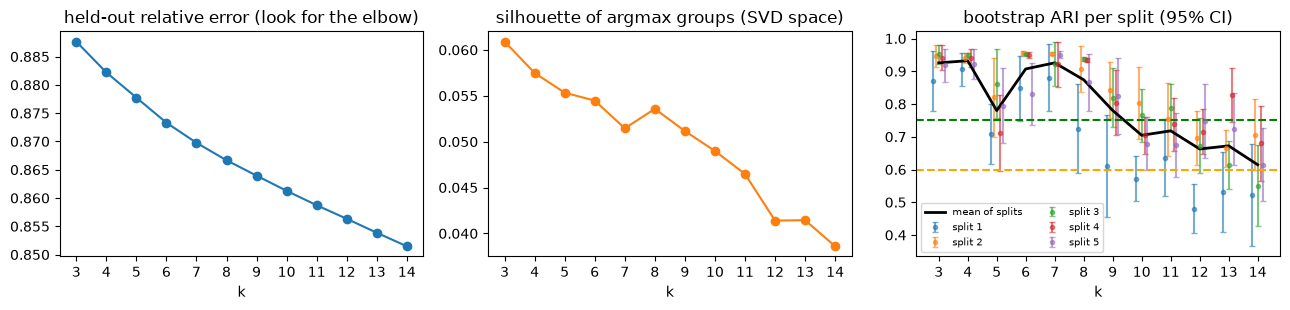

largest k with ARI >= 0.60 on 4+ of 5 splits and mean cos >= 0.75: 13
largest k with ARI >= 0.75 on 4+ of 5 splits and no unstable component (median): 8


In [11]:
import io, contextlib
from joblib import Parallel, delayed
from sklearn.metrics import silhouette_score
from scipy import stats

K_GRID        = list(range(N_CFG['k_min'], N_CFG['k_max'] + 1))
SPLIT_SEEDS_K = tuple(N_CFG['split_seeds'])
N_SWEEP       = min(N_CFG['n_sweep_cap'], int(0.6 * Xs.shape[0]))      # train patients every k is fit on (scales with the cohort)
N_HELD        = min(N_CFG['n_held_cap'], Xs.shape[0] - N_SWEEP)        # disjoint held-out patients for error / silhouette
N_BOOT_K      = N_CFG['n_boot_k']
NC_SIL        = min(24, Z.shape[1])
MIN_SPLITS_K  = math.ceil(N_CFG['min_splits_frac'] * len(SPLIT_SEEDS_K))   # a k must pass on this many splits
N_JOBS        = max(1, (os.cpu_count() or 2) - 2)                      # sklearn's NMF is single-threaded: one fit per core

def rel_err(X, W, H):
    """||X - W H||_F / ||X||_F without building the dense W @ H (X may be sparse)."""
    x2    = X.multiply(X).sum() if sp.issparse(X) else (X ** 2).sum()
    cross = np.sum((X @ H.T) * W)
    quad  = np.sum((W.T @ W) * (H @ H.T))
    return float(np.sqrt(max(x2 - 2 * cross + quad, 0.0) / x2))

def sweep_job(split_seed, k, Xtr, Xho, Zho, n_boot):
    """All metrics for one (split, k): one base fit plus n_boot bootstrap refits."""
    t0 = time.perf_counter()
    m  = NMF(n_components=k, **NMF_KW).fit(Xtr)
    Wh = m.transform(Xho)
    lab_ho = Wh.argmax(1)
    cos, ari = nmf_stability(m, Xtr, n_boot=n_boot, n_sample=Xtr.shape[0], n_eval=Xtr.shape[0], seed=k, verbose=False)
    share = np.bincount(lab_ho, minlength=k) / len(lab_ho)
    return {'split': split_seed, 'k': k,
            'held_out_err': rel_err(Xho, Wh, m.components_),
            'silhouette': silhouette_score(Zho, lab_ho) if len(set(lab_ho)) > 1 else np.nan,
            'ari_mean': ari.mean(), 'ari_sd': ari.std(ddof=1), 'ari_se': ari.std(ddof=1) / np.sqrt(n_boot),
            'cos_mean': cos.mean(), 'n_unstable': int((cos.mean(0) < .75).sum()),
            'n_used': int((share >= .01).sum()), 'secs': time.perf_counter() - t0}

def make_split(split_seed):                                   # sliced once here, so workers get small inputs
    perm   = np.random.default_rng(split_seed).permutation(Xs.shape[0])
    tr, ho = perm[:N_SWEEP], perm[N_SWEEP:N_SWEEP + N_HELD]
    return Xs[tr], Xs[ho], Z[ho, :NC_SIL]                     # Z rows align with Xs rows

splits  = {s: make_split(s) for s in SPLIT_SEEDS_K}
jobs    = [(s, k) for k in sorted(K_GRID, reverse=True) for s in SPLIT_SEEDS_K]   # slow (large k) first
results = Parallel(n_jobs=N_JOBS, verbose=5)(delayed(sweep_job)(s, k, *splits[s], N_BOOT_K) for s, k in jobs)
res       = pd.DataFrame(results)
per_split = {s: res[res.split == s].drop(columns=['split', 'secs']).set_index('k').sort_index() for s in SPLIT_SEEDS_K}
print(f"{len(jobs)} jobs on {N_JOBS} workers; summed fit time {res.secs.sum() / 60:.1f} CPU-min")

g     = pd.concat(per_split, names=['split']).groupby('k')
sweep = pd.DataFrame({'held_out_err': g.held_out_err.mean(), 'silhouette': g.silhouette.mean(),
                      'ari_mean': g.ari_mean.mean(), 'ari_sd_splits': g.ari_mean.std(),
                      'n_splits_solid': g.ari_mean.apply(lambda a: int((a >= .75).sum())),
                      'n_splits_sugg':  g.ari_mean.apply(lambda a: int((a >= .60).sum())),
                      'cos_mean': g.cos_mean.mean(), 'n_unstable': g.n_unstable.median(), 'n_used': g.n_used.min()})
display(sweep.round(3))

t_crit = stats.t.ppf(0.975, N_BOOT_K - 1)    # few refits -> t interval, not 1.96
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].plot(sweep.index, sweep.held_out_err, marker='o'); ax[0].set_title('held-out relative error (look for the elbow)')
ax[1].plot(sweep.index, sweep.silhouette, marker='o', color='C1'); ax[1].set_title('silhouette of argmax groups (SVD space)')
for i, s in enumerate(SPLIT_SEEDS_K):                        # small x-offset so splits do not overlap
    d = per_split[s]
    ax[2].errorbar(d.index + (i - (len(SPLIT_SEEDS_K) - 1) / 2) * 0.1, d.ari_mean, yerr=t_crit * d.ari_se, fmt='o', ms=3, capsize=2, alpha=.6, label=f'split {s}')
ax[2].plot(sweep.index, sweep.ari_mean, 'k-', lw=2, label='mean of splits')
ax[2].axhline(0.75, ls='--', c='green'); ax[2].axhline(0.60, ls='--', c='orange')
ax[2].set_title('bootstrap ARI per split (95% CI)'); ax[2].legend(fontsize=7, ncol=2)
for a in ax: a.set_xlabel('k'); a.set_xticks(sweep.index)
plt.tight_layout(); plt.show()

ok     = sweep[(sweep.n_splits_sugg >= MIN_SPLITS_K) & (sweep.cos_mean >= .75)]
strong = sweep[(sweep.n_splits_solid >= MIN_SPLITS_K) & (sweep.n_unstable == 0)]
print(f"largest k with ARI >= 0.60 on {MIN_SPLITS_K}+ of {len(SPLIT_SEEDS_K)} splits and mean cos >= 0.75:", int(ok.index.max()) if len(ok) else "none")
print(f"largest k with ARI >= 0.75 on {MIN_SPLITS_K}+ of {len(SPLIT_SEEDS_K)} splits and no unstable component (median):", int(strong.index.max()) if len(strong) else "none")

Reading the sweep: held-out error always falls with k (look for the elbow); silhouette is low in absolute terms, read its shape; `n_splits_solid` / `n_splits_sugg` count splits with ARI >= 0.75 / 0.60;
`n_used` counts components that dominate at least 1% of held-out patients (a flat `n_used` means redundant components). No column picks k alone: choose after the error elbow and before stability
collapses, then confirm the components read as distinct clinical bundles. If no k passes the strong rule the next cell falls back to the suggestive rule, and stops if neither passes.

In [12]:
K = K_OVERRIDE or (int(strong.index.max()) if len(strong) else int(ok.index.max()) if len(ok) else None)
assert K is not None, "no k passes the stability rules: set K_OVERRIDE after reading the sweep"
nmf   = NMF(n_components=K, **NMF_KW).fit(Xs)
W     = nmf.transform(Xs)
lab_k = W.argmax(1)                                       # dominant component per patient
H     = pd.DataFrame(nmf.components_, columns=nmf_cols)
dom   = pd.Series(lab_k).value_counts().reindex(range(K), fill_value=0)
NPZ   = os.path.join(RES_DIR, f"nmf_k{K}_{TAG}.npz")
np.savez(NPZ, H=H.to_numpy(), cols=np.array(H.columns, dtype=str), pids=pids, labels=lab_k)
print(f"NMF with {K} components (saved {NPZ})")
for c in range(K):
    row   = H.iloc[c]
    share = (row.sort_values(ascending=False).head(10) / row.sum() * 100).round(1)
    print(f"component {c} (n={dom[c]:,}, {dom[c] / n_pat * 100:.1f}%): {[f'{n[:42]} ({p}%)' for n, p in share.items()]}")

NMF with 8 components (saved outputs/nmf_k8_mammography_v2.npz)
component 0 (n=32,587, 22.9%): ['mammography_screening (3.7%)', 'lipid_panel_this_pan__cpt4__2212095 (3.6%)', 'general_examination___procedure__4036803 (3.4%)', 'periodic_comprehensi__cpt4__2514528 (3.3%)', 'breast_tomosynthesis (3.3%)', 'venipuncture_for_blo__procedure__4102442 (3.2%)', 'chemistry_panel (3.0%)', 'hemoglobin_a1c_measu__procedure__4184637 (2.7%)', 'screening_for_malign__procedure__4147961 (2.4%)', 'active_or_passive_im__procedure__4132855 (2.2%)']
component 1 (n=17,936, 12.6%): ['electrocardiogram_ro__cpt4__2313816 (0.8%)', 'electrocardiogram_ro__cpt4__2313815 (0.8%)', 'troponin_quantitativ__cpt4__2212605 (0.8%)', 'chest_pain__clinical_finding__77670 (0.8%)', 'radiologic_examinati__cpt4__725069 (0.7%)', 'radiologic_examinati__cpt4__725068 (0.7%)', 'dyspnea__clinical_finding__312437 (0.6%)', 'triacylglycerol_lipa__procedure__4021288 (0.6%)', 'therapeutic_prophyla__cpt4__2314215 (0.5%)', 'headache__clinical_f

  boot 1/10  2s  ARI 0.659
  boot 2/10  1s  ARI 0.912
  boot 3/10  1s  ARI 0.650
  boot 4/10  1s  ARI 0.933
  boot 5/10  1s  ARI 0.949
  boot 6/10  1s  ARI 0.925
  boot 7/10  1s  ARI 0.913
  boot 8/10  1s  ARI 0.936
  boot 9/10  1s  ARI 0.662
  boot 10/10  1s  ARI 0.951


,n,top_codes,cos_mean,cos_sd,cos_min,verdict
0,32587,"mammography_screening, lipid_panel_this_pan__cpt4__22, general_examination___procedur",0.999,0.000,0.999,solid
1,17936,"electrocardiogram_ro__cpt4__23, electrocardiogram_ro__cpt4__23, troponin_quantitativ__cpt4__22",0.998,0.000,0.997,solid
2,26265,"21_methylprednisolon__clinical, 6_azithromycin_250_m__clinical, amoxicillin_875_mg_c__clinical",0.999,0.000,0.999,solid
3,17587,"infectious_agent_det__cpt4__22, infectious_agent_det__cpt4__22, cervical_screening",0.998,0.000,0.997,solid
4,10978,"vitamin_b12_measurem__procedur, vitamin_d_25hydroxy___procedur, t4_free_measurement__procedure",0.998,0.000,0.998,solid
5,9908,"therapeutic_procedur__cpt4__23, manual_therapy_techn__cpt4__23, therapeutic_activiti__cpt4__23",0.998,0.000,0.997,solid
6,8500,"ondansetron_injectio__clinical, fentanyl_005_mgml_in__branded_, propofol_injection__clinical_d",0.998,0.000,0.997,solid
7,18822,"level_iv_surgical_pa__cpt4__22, colorectal_screening, screening_for_malign__procedur",0.996,0.001,0.993,solid


bootstrap ARI of argmax labels: mean 0.849  sd 0.126  (>=0.75 solid, >=0.60 suggestive)


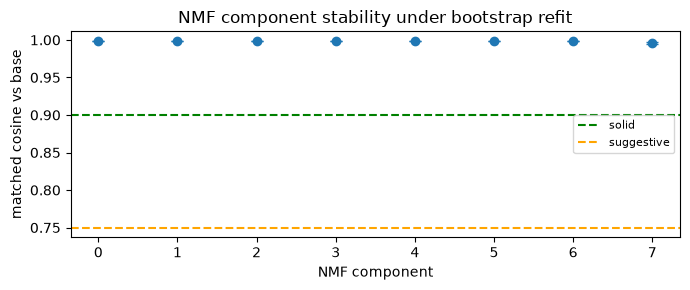

In [13]:
# Stability of the chosen k: bootstrap refits, each component matched to its refit by cosine.
cos, ari = nmf_stability(nmf, Xs)
top3 = [', '.join(H.iloc[c].nlargest(3).index.str.slice(0, 30)) for c in range(K)]
stab = pd.DataFrame({'n': dom.values, 'top_codes': top3, 'cos_mean': cos.mean(0).round(3), 'cos_sd': cos.std(0).round(3), 'cos_min': cos.min(0).round(3)})
stab['verdict'] = np.select([stab.cos_mean >= .90, stab.cos_mean >= .75], ['solid', 'suggestive'], 'unstable')
display(stab)
print(f"bootstrap ARI of argmax labels: mean {ari.mean():.3f}  sd {ari.std():.3f}  (>=0.75 solid, >=0.60 suggestive)")
plt.figure(figsize=(7, 3))
plt.errorbar(stab.index, stab.cos_mean, yerr=stab.cos_sd, fmt='o', capsize=4)
plt.axhline(0.90, ls='--', c='green', label='solid'); plt.axhline(0.75, ls='--', c='orange', label='suggestive')
plt.xlabel('NMF component'); plt.ylabel('matched cosine vs base'); plt.xticks(stab.index); plt.legend(fontsize=8)
plt.title('NMF component stability under bootstrap refit'); plt.tight_layout(); plt.show()

### Where do the clinical codes sit? (loadings check)

The top-10 lists can hide a code that matters but is never in a top 10. For every curated codeset, how its total loading splits across the components (each row sums to 100%).
`owner` is the component with the largest share; `rank_in_owner` is the code's best rank inside that component (1 = its top code). A high share with a rank in the hundreds means the
code attaches to the bundle but does not define it. Codesets that are label proxies are listed first. The label-defining `breast_cancer` codeset is absent by construction (F2).

In [14]:
Hg    = eo.group_loadings(H, events)            # a codeset's loading = sum over the tokens it groups (a token counts in EVERY codeset it is in)
WATCH = {'label proxies':   [t for t in LABEL_PROXY_TAGS],
         'other codesets':  [t for t in codesets if t not in LABEL_PROXY_TAGS and t != 'breast_cancer']}
rows_l, missing = [], []
for grp, tags in WATCH.items():
    for tag in tags:
        if tag not in Hg.columns or Hg[tag].sum() == 0:
            missing.append(tag); continue
        share = Hg[tag] / Hg[tag].sum() * 100
        own   = int(share.values.argmax())
        toks  = list(eo.group_tokens(events, tag) & set(H.columns))
        rows_l.append({'group': grp, 'code': tag, **{f'c{i}': share.iloc[i] for i in range(K)}, 'owner': own,
                       'rank_in_owner': int((H.iloc[own] > H.iloc[own][toks].max()).sum() + 1)})
loadings  = pd.DataFrame(rows_l).set_index(['group', 'code'])
comp_cols = [f'c{i}' for i in range(K)]
display(loadings.style.format({c: '{:.0f}' for c in comp_cols}).background_gradient(axis=1, cmap='Blues', subset=comp_cols))
print(loadings.round(0).astype(int).to_string())                          # the same table as text: share (%) of each codeset's loading per bundle
flat = loadings.reset_index()
print("\nwhere each codeset sits (owner bundle, share >= 30%):")
for i in range(K):
    own = flat[(flat.owner == i) & (flat[f'c{i}'] >= 30)].sort_values(f'c{i}', ascending=False)
    print(f"c{i}: " + (', '.join(f"{c} {v:.0f}" for c, v in zip(own.code, own[f'c{i}'])) or '-'))
loadings.to_csv(os.path.join(RES_DIR, f'loadings_k{K}_{TAG}.csv'))
print("codesets with no column (label, dropped by a filter, the floor or the ceiling, or never occur):", missing or "none")

                                           c0  c1  c2   c3  c4  c5  c6  c7  owner  rank_in_owner
group          code                                                                             
label proxies  in_situ                      0   0   0    0   0   0  63  37      6            598
               lumpectomy                   0   0   0    5   0   0  71  24      6            233
               mastectomy                   0   0   0    3   0   0  90   7      6            548
               lymph_node_procedure         0   0   0    0   0   0  89  11      6            404
               chemotherapy                 0  41   0    0  15   4  31   9      1            862
               antineoplastic_drug          0  10   0    0   0   0  90   0      6            808
               endocrine_therapy            0   0  35   59   0   0   6   0      3            389
               radiation_therapy            0   1   0    0   0   0  69  30      6            604
               receptor_assay 

### What the bundles say about the label — the first answer, with no modelling

For each bundle (patients assigned by their dominant component): how many are breast-cancer patients, the **odds ratio** of being a case inside vs outside the bundle (Haldane +0.5, Woolf 95% CI), a Fisher
p-value with Benjamini-Hochberg q, and the **AUC of the bundle's loading** (a rank statistic of the raw NMF score, nothing is fitted). Two cohort-level numbers say how much of the label the unsupervised
partition recovers: **NMI** and **ARI** between the argmax bundle and the label (0 = unrelated).

A bundle is `cancer-enriched` / `no-cancer-enriched` when its OR interval excludes 1 and q < 0.05, otherwise `mixed`. Read it with the `has_proxy` column: a bundle owned by treatment codes is enriched by construction.

,n,cancer_n,cancer_pct,OR,OR_lo,OR_hi,p,auc_loading,has_proxy_in_top10,top_codes,q,direction
comp,,,,,,,,,,,,
0,32587,127,0.4,0.51,0.43,0.62,4.1e-14,0.458,False,"mammography_screening, lipid_panel_this_pan__cpt4__, general_examination___proced",1.1e-13,no-cancer-enriched
1,17936,200,1.1,1.84,1.57,2.15,9.6e-13,0.614,False,"electrocardiogram_ro__cpt4__, electrocardiogram_ro__cpt4__, troponin_quantitativ__cpt4__",1.9e-12,cancer-enriched
2,26265,88,0.3,0.45,0.36,0.56,9.4e-16,0.400,False,"21_methylprednisolon__clinic, 6_azithromycin_250_m__clinic, amoxicillin_875_mg_c__clinic",3.8e-15,no-cancer-enriched
3,17587,90,0.5,0.74,0.59,0.91,4.3e-03,0.542,False,"infectious_agent_det__cpt4__, infectious_agent_det__cpt4__, cervical_screening",4.3e-03,no-cancer-enriched
4,10978,42,0.4,0.55,0.41,0.75,3.5e-05,0.543,False,"vitamin_b12_measurem__proced, vitamin_d_25hydroxy___proced, t4_free_measurement__procedu",4.6e-05,no-cancer-enriched
5,9908,40,0.4,0.59,0.43,0.80,3.5e-04,0.548,False,"therapeutic_procedur__cpt4__, manual_therapy_techn__cpt4__, therapeutic_activiti__cpt4__",4.0e-04,no-cancer-enriched
6,8500,174,2.0,3.54,3.00,4.18,4.7e-39,0.686,False,"ondansetron_injectio__clinic, fentanyl_005_mgml_in__brande, propofol_injection__clinical",3.7e-38,cancer-enriched
7,18822,201,1.1,1.75,1.50,2.04,4.3e-11,0.630,False,"level_iv_surgical_pa__cpt4__, colorectal_screening, screening_for_malign__proced",6.8e-11,cancer-enriched


base rate 0.7%;  NMI(argmax bundle, label) = 0.001;  ARI = 0.001;  cancer-enriched bundles: 3 of 8


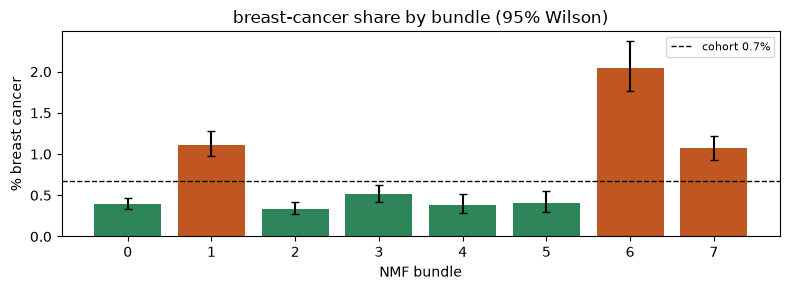

In [15]:
from scipy.stats import fisher_exact
from sklearn.metrics import normalized_mutual_info_score, roc_auc_score
from motif_robustness.scoring import or_ci, bh_fdr, wilson

PROXY_TOK = eo.group_tokens(events, LABEL_PROXY_TAGS) & set(nmf_cols)        # concept tokens that belong to a label-proxy codeset
rows_c = []
for c in range(K):
    m = lab_k == c
    a, n1, b, n2 = int(y[m].sum()), int(m.sum()), int(y[~m].sum()), int((~m).sum())
    lor, lo, hi = or_ci(a, n1, b, n2)
    top10 = H.iloc[c].nlargest(10).index
    rows_c.append({'comp': c, 'n': n1, 'cancer_n': a, 'cancer_pct': 100 * a / max(n1, 1),
                   'OR': float(np.exp(lor)), 'OR_lo': float(np.exp(lo)), 'OR_hi': float(np.exp(hi)),
                   'p': fisher_exact([[a, n1 - a], [b, n2 - b]])[1] if n1 and n2 else np.nan,
                   'auc_loading': roc_auc_score(y, W[:, c]) if len(set(y)) > 1 else np.nan,
                   'has_proxy_in_top10': bool(set(top10) & PROXY_TOK),
                   'top_codes': ', '.join(top10[:3].str.slice(0, 28))})
comp_lab = pd.DataFrame(rows_c).set_index('comp')
comp_lab['q'] = bh_fdr(comp_lab.p.to_numpy())
comp_lab['direction'] = np.select([(comp_lab.OR_lo > 1) & (comp_lab.q < .05), (comp_lab.OR_hi < 1) & (comp_lab.q < .05)],
                                  ['cancer-enriched', 'no-cancer-enriched'], 'mixed')
base = y.mean()
display(comp_lab.style.format({'cancer_pct': '{:.1f}', 'OR': '{:.2f}', 'OR_lo': '{:.2f}', 'OR_hi': '{:.2f}', 'p': '{:.1e}', 'q': '{:.1e}', 'auc_loading': '{:.3f}'}))
print(f"base rate {base:.1%};  NMI(argmax bundle, label) = {normalized_mutual_info_score(y, lab_k):.3f};  ARI = {adjusted_rand_score(y, lab_k):.3f};  "
      f"cancer-enriched bundles: {(comp_lab.direction == 'cancer-enriched').sum()} of {K}")

fig, ax = plt.subplots(figsize=(8, 3))
lo_, hi_ = wilson(comp_lab.cancer_n, comp_lab.n)
ax.bar(comp_lab.index, 100 * comp_lab.cancer_n / comp_lab.n, color=comp_lab.direction.map({'cancer-enriched': '#c05621', 'no-cancer-enriched': '#2f855a', 'mixed': '#a0aec0'}),
       yerr=np.clip([100 * (comp_lab.cancer_n / comp_lab.n - lo_), 100 * (hi_ - comp_lab.cancer_n / comp_lab.n)], 0, None), capsize=3)
ax.axhline(100 * base, ls='--', c='k', lw=1, label=f'cohort {base:.1%}'); ax.set_xticks(comp_lab.index)
ax.set_xlabel('NMF bundle'); ax.set_ylabel('% breast cancer'); ax.legend(fontsize=8); ax.set_title('breast-cancer share by bundle (95% Wilson)')
plt.tight_layout(); plt.show()

**NMF bundles as a table** for the underwriter review: n (%), the top-5 OMOP entities (name, vocabulary + code, concept_id, share of the bundle's patients), the cancer share of the bundle and two empty
columns to fill in. Written to `outputs/nmf_components_<cohort>_k<k>_<variant>.xlsx`. `RANK_BY = 'prevalence'` ranks by how many of the bundle's patients have the code instead of by NMF loading.

In [16]:
try:
    import openpyxl
except ImportError as e:
    raise ImportError("pip install openpyxl in this kernel's environment, then rerun this cell") from e
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

RANK_BY  = 'loading'        # 'loading' = codes that define the bundle (NMF loading); 'prevalence' = codes most patients of the bundle have
TOP_N    = 5
XLSX_NMF = os.path.join(RES_DIR, f"nmf_components_{COHORT}_k{K}_{VARIANT}.xlsx")
meta     = events.drop_duplicates('tag').set_index('tag')

# TOKEN_LEVEL == 'group': a token can be a codeset tag that collapses several concepts, so there is no single concept_id to print.
# Show the tag, how many concepts it holds in this cohort and its most frequent member. (_n_members, _is_group_token, _top_member
# are reused by the components-json cell below.)
_n_members = events[['tag', 'concept_id']].drop_duplicates().groupby('tag').size()
def _is_group_token(tok):
    return TOKEN_LEVEL == 'group' and tok in codesets and _n_members.get(tok, 0) > 0
def _top_member(tok):
    sub = events.loc[events['tag'] == tok, ['concept_id', 'concept_name', 'vocabulary_id', 'concept_code']]
    return sub[sub['concept_id'] == sub['concept_id'].value_counts().index[0]].iloc[0]
def _group_entity(tok, prev):
    m, n = _top_member(tok), int(_n_members[tok])
    return f"{tok} [codeset: {n} concept{'s' if n != 1 else ''}; most frequent {m.vocabulary_id} {m.concept_code} {str(m.concept_name)[:40]}] ({prev:.0%} of bundle)"

def entity(tok, prev):
    if _is_group_token(tok):
        return _group_entity(tok, prev)
    r = meta.loc[tok]
    name = re.split(r' \(|;| This ', str(r.concept_name))[0].strip()
    name = name if len(name) >= 8 else str(r.concept_name)          # packs like '{6 (azithromycin ...) } Pack' would be cut to '{6'
    name = name if len(name) <= 60 else name[:60].rsplit(' ', 1)[0] + '…'
    return f"{name} [{r.vocabulary_id} {r.concept_code}] (concept_id {int(r.concept_id)}; {prev:.0%} of bundle)"

rows_e = []
for c in range(K):
    members = np.flatnonzero(lab_k == c)
    prev  = pd.Series(np.asarray(Xs[members].mean(axis=0)).ravel(), index=nmf_cols)     # share of the bundle's patients with each code
    score = H.iloc[c] if RANK_BY == 'loading' else prev
    top   = score.nlargest(TOP_N).index
    r_    = comp_lab.loc[c]
    rows_e.append({'Group': f"c{c}", 'n (%)': f"{len(members):,} ({len(members) / n_pat:.1%})",
                   'Most frequently OMOP clinical entities found': "\n".join(f"{i}. {entity(t, prev[t])}" for i, t in enumerate(top, 1)),
                   'Breast cancer in bundle': f"{int(r_.cancer_n):,} ({r_.cancer_pct:.1f}%)  OR {r_.OR:.1f} ({r_.OR_lo:.1f}-{r_.OR_hi:.1f})  {r_.direction}",
                   'Suggested Clinical Pathway': '', 'UW suggestion': ''})
nmf_table = pd.DataFrame(rows_e)

F = lambda **kw: Font(name='Arial', size=10, **kw)
thin = Side(style='thin', color='D0D5DB')
wb = openpyxl.Workbook(); ws = wb.active; ws.title = f'NMF k={K}'
ws.append(list(nmf_table.columns))
for j in range(1, ws.max_column + 1):
    h = ws.cell(1, j); h.font = Font(name='Arial', size=10, bold=True, color='FFFFFF')
    h.fill = PatternFill('solid', fgColor='334E68'); h.alignment = Alignment(wrap_text=True, vertical='center', horizontal='center')
ws.row_dimensions[1].height = 30
for row in nmf_table.itertuples(index=False):
    ws.append(list(row))
for i in range(2, len(nmf_table) + 2):
    ws.row_dimensions[i].height = 15 * TOP_N + 6
    for j in range(1, ws.max_column + 1):
        c_ = ws.cell(i, j); c_.font = F(bold=(j == 1)); c_.border = Border(bottom=thin)
        c_.alignment = Alignment(wrap_text=True, vertical='top', horizontal='center' if j in (1, 2) else 'left')
for j, w in enumerate([14, 16, 95, 34, 40, 40], 1):
    ws.column_dimensions[get_column_letter(j)].width = w
ws.freeze_panes = 'B2'
ws.cell(len(nmf_table) + 3, 1, f"Source: {TAG}, NMF k={K} on {TOKEN_LEVEL}-level tokens, codesets {CODESETS_FILE} ({n_pat:,} patients). n (%) = patients whose dominant component is the bundle. "
        f"Entities ranked by {'NMF loading in the bundle' if RANK_BY == 'loading' else 'share of the bundle patients having the code'}; the percentage is the share of the bundle's patients with that code. "
        "'Breast cancer in bundle' is read AFTER the fit (the label never enters NMF). The last two columns are left empty on purpose.").font = F(italic=True)
wb.save(XLSX_NMF)
print(f"wrote {os.path.abspath(XLSX_NMF)} ({K} bundles)")
nmf_table

wrote /Users/esteban.correaagudelo/codeprojects/ethos_foundation_llm/nb/repr_learn_mammography/outputs/nmf_components_mammography_k8_v2.xlsx (8 bundles)


,Group,n (%),Most frequently OMOP clinical entities found,Breast cancer in bundle,Suggested Clinical Pathway,UW suggestion
0,c0,"32,587 (22.9%)","1. mammography_screening [codeset: 3 concepts; most frequent CPT4 77067 Screening mammography, bilateral (2-view] (9...",127 (0.4%) OR 0.5 (0.4-0.6) no-cancer-enriched,,
1,c1,"17,936 (12.6%)","1. Electrocardiogram, routine ECG with at least 12 leads [CPT4 93010] (concept_id 2313816; 72% of bundle)\n2. Electr...",200 (1.1%) OR 1.8 (1.6-2.1) cancer-enriched,,
2,c2,"26,265 (18.4%)",1. {21 (methylprednisolone 4 MG Oral Tablet) } Pack [RxNorm 762675] (concept_id 19129398; 57% of bundle)\n2. {6 (azi...,88 (0.3%) OR 0.4 (0.4-0.6) no-cancer-enriched,,
3,c3,"17,587 (12.3%)",1. Infectious agent detection by nucleic acid [CPT4 87491] (concept_id 2213115; 69% of bundle)\n2. Infectious agent ...,90 (0.5%) OR 0.7 (0.6-0.9) no-cancer-enriched,,
4,c4,"10,978 (7.7%)","1. Vitamin B12 measurement [SNOMED 14598005] (concept_id 4032173; 85% of bundle)\n2. Vitamin D, 25-hydroxy measureme...",42 (0.4%) OR 0.6 (0.4-0.8) no-cancer-enriched,,
5,c5,"9,908 (6.9%)","1. Therapeutic procedure, 1 or more areas, each 15 minutes [CPT4 97110] (concept_id 2314284; 90% of bundle)\n2. Manu...",40 (0.4%) OR 0.6 (0.4-0.8) no-cancer-enriched,,
6,c6,"8,500 (6.0%)",1. ondansetron Injection [RxNorm 1740463] (concept_id 35605480; 96% of bundle)\n2. fentanyl 0.05 MG/ML Injection [Su...,174 (2.0%) OR 3.5 (3.0-4.2) cancer-enriched,,
7,c7,"18,822 (13.2%)","1. Level IV - Surgical pathology, gross and microscopic… [CPT4 88305] (concept_id 2213283; 81% of bundle)\n2. colore...",201 (1.1%) OR 1.7 (1.5-2.0) cancer-enriched,,


In [17]:
# Persist the bundles next to the .npz: n, top tokens with concept ids, a signature, the cancer read-out and the NAMES you give them.
# Part B loads this file for the component names. Workflow: run once -> fill DESCR below from the printed template -> run again.
# A saved name survives a re-run only while the component's top-5 tokens are unchanged.
# NOTE (in-situ): in-situ-only patients (DCIS / LCIS) are kept by default (DROP_INSITU_ONLY = False): pre-cancer, some risk, manual review.
# When a bundle holds them (the in_situ row of the codeset loadings, cell 25), say so in its name.
DESCR     = {}      # {component: 'name'}, e.g. {0: 'preventive screening and labs'}; empty = auto-named from the top tokens
# First run: leave DESCR empty, read the printed bundles at the bottom, paste the names here and re-run. The v1 names (`full` run, k=9) are not reused: the bundles differ.
DESCR = {
    0: 'preventive check-up and screening (screening mammography, tomosynthesis, preventive visit, lipid panel, HbA1c, chemistry panel, CBC, immunization; type 2 diabetes and obesity)',
    1: 'cardiac / chest-pain acute workup (ECG, troponin, chest X-ray, dyspnea, lipase, headache; also chemotherapy and bone scan / PET codes)',
    2: 'acute-illness prescriptions (steroids, antibiotics for respiratory and urinary infection, antifungal, nasal steroid; menopausal hormone therapy)',
    3: "women's health and breast-imaging workup (gyn exam, cervical screening, STI nucleic-acid and urine tests, pregnancy and contraception, transvaginal and breast ultrasound, diagnostic mammography, breast symptoms, BRCA / genetic counseling)",
    4: 'endocrine and nutrient labs (B12, vitamin D, free T4 / T3, iron studies, FSH / estradiol / testosterone)',
    5: 'physical therapy and musculoskeletal pain (back, neck, shoulder; manual therapy, chiropractic)',
    6: 'peri-operative and breast-cancer surgical treatment (anesthesia, antiemetic, antibiotic and analgesic IV drugs, mastectomy, lumpectomy, lymph nodes, reconstruction, radiation, antineoplastics; most of the in-situ disease codes)',
    7: 'colorectal screening, surgical pathology and dermatology (colonoscopy anesthesia, uncertain neoplasm, skin lesions; breast MRI, density, findings, biopsy, benign breast disease; part of the in-situ disease codes)',
}

JSON_PATH = os.path.join(RES_DIR, f"nmf_k{K}_{TAG}_components.json")
TOP_J     = 10
meta_j = events.drop_duplicates('tag').set_index('tag')
old    = json.load(open(JSON_PATH))['components'] if os.path.exists(JSON_PATH) else {}

comps = {}
for c in range(K):
    row  = H.iloc[c]
    sig  = list(row.nlargest(5).index)
    toks = []
    for t, v in row.nlargest(TOP_J).items():
        if _is_group_token(t):                      # codeset tag: no single concept (helpers defined in the components-table cell)
            m = _top_member(t)
            toks.append(dict(token=t, concept_id=None, concept_name=f"[codeset {t}] {int(_n_members[t])} concepts; most frequent: {m.concept_name}",
                             vocabulary_id='codeset', concept_code='', n_concepts=int(_n_members[t]),
                             loading=round(float(v), 6), share_pct=round(float(v / row.sum() * 100), 1)))
            continue
        m = meta_j.loc[t]
        toks.append(dict(token=t, concept_id=int(m.concept_id), concept_name=str(m.concept_name), vocabulary_id=str(m.vocabulary_id),
                         concept_code=str(m.concept_code), loading=round(float(v), 6), share_pct=round(float(v / row.sum() * 100), 1)))
    keep = old.get(str(c), {})
    keep = keep if set(keep.get('signature', [])) == set(sig) else {}
    r_   = comp_lab.loc[c]
    comps[str(c)] = dict(n=int(r_.n), pct=round(r_.n / n_pat * 100, 2), signature=sig, name=DESCR.get(c, keep.get('name')),
                         cancer_n=int(r_.cancer_n), cancer_pct=round(r_.cancer_pct, 2), OR=round(r_.OR, 2), direction=r_.direction, top_tokens=toks)
out = dict(cohort=COHORT, variant=VARIANT, k=int(K), npz=NPZ, n_patients=int(n_pat), components=comps,
           npz_sha256=hashlib.sha256(open(NPZ, 'rb').read()).hexdigest())
with open(JSON_PATH, 'w') as f:
    json.dump(out, f, indent=2, ensure_ascii=False)
print(f"saved {JSON_PATH}  (k={K}, {n_pat:,} patients)\n")
print(f"{'comp':>4} {'n':>7} {'%':>5} {'cancer%':>8}  {'direction':<19} name  |  top tokens")
for c, d in comps.items():
    print(f"{c:>4} {d['n']:>7,} {d['pct']:5.1f} {d['cancer_pct']:8.1f}  {d['direction']:<19} {d['name'] or '(unnamed)'}  |  " + ', '.join(t['token'].split('__')[0] for t in d['top_tokens'][:4]))
print("\n# paste-ready DESCR (edit the names, then re-run this cell):\nDESCR = {")
for c, d in comps.items():
    print(f"    {c}: {d['name']!r},")
print("}")

saved outputs/nmf_k8_mammography_v2_components.json  (k=8, 142,583 patients)

comp       n     %  cancer%  direction           name  |  top tokens
   0  32,587  22.9      0.4  no-cancer-enriched  preventive check-up and screening (screening mammography, tomosynthesis, preventive visit, lipid panel, HbA1c, chemistry panel, CBC, immunization; type 2 diabetes and obesity)  |  mammography_screening, lipid_panel_this_pan, general_examination, periodic_comprehensi
   1  17,936  12.6      1.1  cancer-enriched     cardiac / chest-pain acute workup (ECG, troponin, chest X-ray, dyspnea, lipase, headache; also chemotherapy and bone scan / PET codes)  |  electrocardiogram_ro, electrocardiogram_ro, troponin_quantitativ, chest_pain
   2  26,265  18.4      0.3  no-cancer-enriched  acute-illness prescriptions (steroids, antibiotics for respiratory and urinary infection, antifungal, nasal steroid; menopausal hormone therapy)  |  21_methylprednisolon, 6_azithromycin_250_m, amoxicillin_875_mg_c, predniso

# Part B · Day 3 — ordered motifs, by bundle and by label

## 3 · Sequences

One ordered token list per patient, from the **same events as the NMF** (`ev_keep`: after every filter and the F7 prevalence floor / ceiling, so Part A and Part B see identical patients and codes).

Two arbitrary choices, both written down: (1) **same-day ties**: claims carry a date, `eo.DOMAIN_ORDER` breaks ties (condition, procedure, measurement, drug); (2) **refill collapsing**: consecutive repeats of
one token become one step, otherwise every pattern is `X -> X -> X`. Visits are not in the sequence at all (F1).

`build_patient_seqs` also keeps the first date of every step, which the strict-date matching and the timing columns need; the check below confirms it agrees with `eo.sequences`.

In [18]:
from motif_robustness.preprocess import build_patient_seqs, sequences_with_dates

pids_s, patseqs = build_patient_seqs(ev_keep)
assert list(pids_s) == list(pids), "sequence patients differ from the NMF rows"
_chk = eo.sequences(ev_keep, col='tag', dedup_same_day=True, collapse_repeats=True)
assert all(_chk[p] == ps.tokens for p, ps in zip(pids_s, patseqs)), "dated sequences differ from eo.sequences"
del _chk
lens = np.array([len(ps.tokens) for ps in patseqs])
print(f"{len(patseqs):,} sequences; median length {int(np.median(lens))} steps (cases {int(np.median(lens[y == 1]))}, controls {int(np.median(lens[y == 0]))})")
print("example timeline:", ' -> '.join(t[:28] for t in patseqs[1].tokens[:8]))

142,583 sequences; median length 182 steps (cases 296, controls 181)
example timeline: periodic_comprehensi__cpt4__ -> venipuncture_for_blo__proced -> gynecologic_examinat__proced -> acute_hepatitis_pane__cpt4__ -> infectious_agent_det__cpt4__ -> infectious_agent_det__cpt4__ -> cervical_screening -> screening_for_malign__proced


In [19]:
# Names of the bundles: auto-names from the top tokens, replaced by the names saved in the components JSON (Part A, last cell)
# for every component whose top-5 tokens still match (>= 4 of 5).
COMP = {c: f"c{c}: " + ', '.join(H.iloc[c].nlargest(3).index.str.split('__').str[0]) for c in range(K)}
if os.path.exists(JSON_PATH):
    J = json.load(open(JSON_PATH))['components']
    for c in range(K):
        j = J.get(str(c), {})
        if not j.get('name'):
            continue
        if len(set(j['signature']) & set(H.iloc[c].nlargest(5).index)) < 4:
            print(f"WARNING c{c}: top tokens in the JSON differ from this NMF, its name is ignored"); continue
        COMP[c] = f"c{c}: {j['name']}"
_descr = globals().get('DESCR') or {}          # cell 30: a non-empty DESCR entry wins over the saved JSON name and the auto-name; empty = keep the current name
for c in range(K):
    if _descr.get(c):
        COMP[c] = f"c{c}: {_descr[c]}"
LAB_NAME = {0: 'no breast cancer', 1: 'breast cancer'}
comp_n = pd.Series(lab_k).value_counts().reindex(range(K), fill_value=0)
display(pd.DataFrame({'n': comp_n, 'cancer_pct': comp_lab.cancer_pct.round(1), 'direction': comp_lab.direction, 'name': pd.Series(COMP)}))

,n,cancer_pct,direction,name
0,32587,0.4,no-cancer-enriched,"c0: preventive check-up and screening (screening mammography, tomosynthesis, preventive visit, lipid panel, HbA1c, c..."
1,17936,1.1,cancer-enriched,"c1: cardiac / chest-pain acute workup (ECG, troponin, chest X-ray, dyspnea, lipase, headache; also chemotherapy and ..."
2,26265,0.3,no-cancer-enriched,"c2: acute-illness prescriptions (steroids, antibiotics for respiratory and urinary infection, antifungal, nasal ster..."
3,17587,0.5,no-cancer-enriched,"c3: women's health and breast-imaging workup (gyn exam, cervical screening, STI nucleic-acid and urine tests, pregna..."
4,10978,0.4,no-cancer-enriched,"c4: endocrine and nutrient labs (B12, vitamin D, free T4 / T3, iron studies, FSH / estradiol / testosterone)"
5,9908,0.4,no-cancer-enriched,"c5: physical therapy and musculoskeletal pain (back, neck, shoulder; manual therapy, chiropractic)"
6,8500,2.0,cancer-enriched,"c6: peri-operative and breast-cancer surgical treatment (anesthesia, antiemetic, antibiotic and analgesic IV drugs, ..."
7,18822,1.1,cancer-enriched,"c7: colorectal screening, surgical pathology and dermatology (colonoscopy anesthesia, uncertain neoplasm, skin lesio..."


## 4 · Discovery — PrefixSpan inside each group, two groupings

Raw support finds whatever is common, which is mostly ambient care. What matters is a pattern common **inside** a group and rare **outside** it. `discover()` (in `motif_robustness/discovery.py`) runs, per group:

1. **Mining** (local PrefixSpan on the group's own patients, so a global floor does not bury small groups): ordered patterns of 3-4 steps present in >= `rel_sup` of the group. Groups larger than `mine_cap` are mined on a random sample of that size (runtime only; every candidate is scored on every patient of the group).
2. **Scoring**: `sup_in`, `sup_out` (a fixed random sample of the other patients), `lift = (sup_in + .01) / (sup_out + .01)`.
3. **Bootstrap** of the lift (`lift_lo`, `lift_hi`): is the number steady?
4. **Split seeds**: nominate on one random half, score on the other, 5 times (`splits_found`). `verdict`: **solid** = found in >= 4 of 5 and `lift_lo >= min_lift`, **suggestive** = 3 of 5, else **unstable**.
5. **Held-out pass rate per motif family** (40 half-splits, lower odds-ratio bound against ALL outside patients) -> `hybrid_verdict`: a `solid` motif whose family pass rate is not reliably high is downgraded to `suggestive`.

The two groupings, run blind to each other:

- **by NMF bundle** (`lab_k`): what care sequences characterise each unsupervised bundle;
- **by label** (`y`): what sequences are more common in breast-cancer patients than in the others (group `breast cancer`) and the reverse (group `no breast cancer`). The label here only *defines the groups being compared*; nothing is fitted.

Knobs live in `config/robustness.yaml`. `has_proxy` marks motifs containing a cancer treatment / staging code (`LABEL_PROXY_TAGS`): those are expected, so read the unflagged ones as the finding.
Runtime is not measured yet; the cost is PrefixSpan on `mine_cap` patients per group and the all-patient hit matrices of the held-out step.

In [20]:
from motif_robustness.discovery import discover
M_, S_, ST_, HO_ = CFG['mining'], CFG['scoring'], CFG['stability'], CFG['heldout']
P = dict(rel_sup=M_['rel_sup'], max_len=M_['max_len'], min_len=M_['min_len'], max_cand=M_['max_cand'], mine_cap=M_['mine_cap'], n_out=M_['n_out'],
         min_group_n=M_['min_group_n'], min_lift=S_['min_lift'], n_boot=S_['n_boot'],
         split_seeds=tuple(ST_['split_seeds']), min_splits_ok=ST_['min_splits_ok'],
         ho_seeds=tuple(range(HO_['seeds_from'], HO_['seeds_from'] + HO_['n_seeds'])), ho_min_or=HO_['min_or'], ho_min_rate_lo=HO_['min_rate_lo'],
         fam_dist=HO_['fam_dist'], same_day_ratio=HO_['same_day_ratio'], seed=CFG['seed'], n_jobs=N_JOBS)

def flag_proxy(rows):
    """has_proxy: the motif contains a token of a label-proxy codeset."""
    for d in rows.values():
        if len(d):
            d['has_proxy'] = d.pattern.map(lambda p: any(t in PROXY_TOK for t in p.split(' -> ')))
    return rows

t0 = time.perf_counter()
rows_lab = flag_proxy(discover(patseqs, y, **P))
print(f"by label: {(time.perf_counter() - t0) / 60:.1f} min")

[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done   2 out of   2 | elapsed:  1.7min finished
[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done   2 out of  10 | elapsed:  1.4min remaining:  5.5min
[Parallel(n_jobs=12)]: Done   5 out of  10 | elapsed:  1.5min remaining:  1.5min
[Parallel(n_jobs=12)]: Done   8 out of  10 | elapsed:  1.8min remaining:   26.7s
[Parallel(n_jobs=12)]: Done  10 out of  10 | elapsed:  2.1min finished


by label: 4.6 min


In [21]:
t0 = time.perf_counter()
rows_comp = flag_proxy(discover(patseqs, lab_k, **P))
print(f"by NMF bundle: {(time.perf_counter() - t0) / 60:.1f} min;  bundles mined: {sorted(rows_comp)} of {K} "
      f"(groups under min_group_n={M_['min_group_n']} are skipped)")

[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done   3 out of   8 | elapsed:  2.1min remaining:  3.5min
[Parallel(n_jobs=12)]: Done   5 out of   8 | elapsed:  4.2min remaining:  2.5min
[Parallel(n_jobs=12)]: Done   8 out of   8 | elapsed: 18.0min finished
[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 out of  40 | elapsed: 15.4min remaining:  8.3min
[Parallel(n_jobs=12)]: Done  35 out of  40 | elapsed: 23.6min remaining:  3.4min
[Parallel(n_jobs=12)]: Done  40 out of  40 | elapsed: 24.9min finished


by NMF bundle: 44.2 min;  bundles mined: [0, 1, 2, 3, 4, 5, 6, 7] of 8 (groups under min_group_n=50 are skipped)


In [22]:
# readable patterns: concept name [vocabulary code] per step; the tokens are <name20>__<class>__<concept_id>
cdx = concept.drop_duplicates('concept_id').set_index('concept_id')
def _condense(n, limit=38):
    s = re.split(r' \(|;| This ', n)[0].strip()
    s = s if len(s) >= 8 else n                                      # packs like '{6 (azithromycin ...) } Pack' would be cut to '{6'
    return s if len(s) <= limit else s[:limit].rsplit(' ', 1)[0] + '…'
def label(token):
    m = re.search(r'__(\d+)$', token)
    if m and int(m.group(1)) in cdx.index:
        r = cdx.loc[int(m.group(1))]
        return f"{_condense(r.concept_name)} [{r.vocabulary_id} {r.concept_code}]"
    return f"{token.replace('_', ' ')} [code group]"
def pattern_text(pattern):
    parts = []
    for t, g in itertools.groupby(pattern.split(' -> ')):
        n = len(list(g)); parts.append(label(t) + (f" ×{n}" if n > 1 else ""))
    return ' → '.join(parts)

def summarize(rows, names, groups):
    out = []
    for g in sorted(rows):
        d = rows[g]; v = d.hybrid_verdict.value_counts() if len(d) else pd.Series(dtype=int)
        out.append({'group': names[g], 'n': int((groups == g).sum()), 'motifs': len(d), 'solid': int(v.get('solid', 0)),
                    'suggestive': int(v.get('suggestive', 0)), 'unstable': int(v.get('unstable', 0)),
                    'solid, no proxy': int(((d.hybrid_verdict == 'solid') & ~d.has_proxy).sum()) if len(d) else 0,
                    'max lift (solid)': float(d.loc[d.hybrid_verdict == 'solid', 'lift'].max()) if len(d) and (d.hybrid_verdict == 'solid').any() else np.nan})
    return pd.DataFrame(out).set_index('group')

SHOW  = ['pattern', 'sup_in', 'sup_out', 'lift', 'lift_lo', 'lift_hi', 'splits_found', 'hybrid_verdict', 'same_day_bundle', 'has_proxy']
_RANK = {'solid': 0, 'suggestive': 1, 'unstable': 2}
def top_motifs(d, n=6):
    d = d.assign(_o=d.hybrid_verdict.map(_RANK)).sort_values(['_o', 'lift'], ascending=[True, False]).head(n)
    return d.assign(pattern=d.pattern.map(pattern_text))[SHOW]

print("by label"); display(summarize(rows_lab, LAB_NAME, y))
print("by NMF bundle"); display(summarize(rows_comp, COMP, lab_k))

by label


,n,motifs,solid,suggestive,unstable,"solid, no proxy",max lift (solid)
group,,,,,,,
no breast cancer,141621,100,0,0,100,0,NaN
breast cancer,962,100,1,4,95,1,3.9


by NMF bundle


,n,motifs,solid,suggestive,unstable,"solid, no proxy",max lift (solid)
group,,,,,,,
"c0: preventive check-up and screening (screening mammography, tomosynthesis, preventive visit, lipid panel, HbA1c, chemistry panel, CBC, immunization; type 2 diabetes and obesity)",32587,100,0,0,100,0,NaN
"c1: cardiac / chest-pain acute workup (ECG, troponin, chest X-ray, dyspnea, lipase, headache; also chemotherapy and bone scan / PET codes)",17936,100,48,20,32,48,5.0
"c2: acute-illness prescriptions (steroids, antibiotics for respiratory and urinary infection, antifungal, nasal steroid; menopausal hormone therapy)",26265,100,15,0,85,15,3.6
"c3: women's health and breast-imaging workup (gyn exam, cervical screening, STI nucleic-acid and urine tests, pregnancy and contraception, transvaginal and breast ultrasound, diagnostic mammography, breast symptoms, BRCA / genetic counseling)",17587,100,14,0,86,14,7.5
"c4: endocrine and nutrient labs (B12, vitamin D, free T4 / T3, iron studies, FSH / estradiol / testosterone)",10978,100,44,5,51,44,5.6
"c5: physical therapy and musculoskeletal pain (back, neck, shoulder; manual therapy, chiropractic)",9908,100,87,2,11,87,5.9
"c6: peri-operative and breast-cancer surgical treatment (anesthesia, antiemetic, antibiotic and analgesic IV drugs, mastectomy, lumpectomy, lymph nodes, reconstruction, radiation, antineoplastics; most of the in-situ disease codes)",8500,100,71,0,29,71,13.9
"c7: colorectal screening, surgical pathology and dermatology (colonoscopy anesthesia, uncertain neoplasm, skin lesions; breast MRI, density, findings, biopsy, benign breast disease; part of the in-situ disease codes)",18822,100,13,0,87,13,3.8


### The motifs

Per group, the six best motifs (solid first, then by lift). `sup_in` / `sup_out` = share of the group / of the others with the ordered pattern; `lift_lo`-`lift_hi` = bootstrap 95% range;
`splits_found` = re-found in how many of 5 splits; `same_day_bundle` = with every step on a strictly later day support falls below half, so the "order" is mostly a tie-break; `has_proxy` = contains a cancer treatment / staging code.

**What this does not test.** The bundle labels come from the full-data NMF, so bundle verdicts are stability *given* those labels. The top motifs inside a group are often variants of each other (same codes, one extra step);
`fam_id` in `rows_*` groups them, one real pathway can fill several rows. Only motifs reaching `rel_sup` inside the group are tested at all: a true but rare motif never becomes a candidate.

In [23]:
with pd.option_context('display.max_colwidth', 150):
    for g in sorted(rows_lab):
        print(f"\n===== by label: {LAB_NAME[g]}  (n={int((y == g).sum()):,})")
        display(top_motifs(rows_lab[g]) if len(rows_lab[g]) else "no ordered pattern of >= 3 steps reaches the in-group support floor")


===== by label: no breast cancer  (n=141,621)


,pattern,sup_in,sup_out,lift,lift_lo,lift_hi,splits_found,hybrid_verdict,same_day_bundle,has_proxy
0,cervical screening [code group] → mammography screening [code group] → breast tomosynthesis [code group],0.422,0.337,1.2,1.1,1.4,0,unstable,False,False
1,General examination of patient [SNOMED 162673000] → mammography screening [code group] → breast tomosynthesis [code group],0.495,0.415,1.2,1.1,1.3,0,unstable,False,False
2,Gynecologic examination [SNOMED 83607001] → mammography screening [code group] → breast tomosynthesis [code group],0.446,0.359,1.2,1.1,1.3,0,unstable,False,False
3,Lipid panel [CPT4 80061] → mammography screening [code group] → breast tomosynthesis [code group],0.541,0.464,1.2,1.1,1.2,0,unstable,False,False
4,Periodic comprehensive preventive… [CPT4 99396] → General examination of patient [SNOMED 162673000] → mammography screening [code group],0.425,0.362,1.2,1.1,1.3,0,unstable,False,False
5,Periodic comprehensive preventive… [CPT4 99396] → General examination of patient [SNOMED 162673000] → mammography screening [code group] → breast ...,0.407,0.349,1.2,1.1,1.3,0,unstable,True,False



===== by label: breast cancer  (n=962)


,pattern,sup_in,sup_out,lift,lift_lo,lift_hi,splits_found,hybrid_verdict,same_day_bundle,has_proxy
0,mammography diagnostic [code group] → chemistry panel [code group] → cbc [code group],0.573,0.141,3.9,3.4,4.4,5,solid,False,False
1,mammography diagnostic [code group] → Venipuncture for blood test [SNOMED 28520004] → chemistry panel [code group],0.547,0.151,3.5,3.1,3.9,3,suggestive,False,False
3,cbc [code group] → chemistry panel [code group] ×2 → cbc [code group],0.552,0.267,2.0,1.8,2.2,3,suggestive,False,False
5,chemistry panel [code group] ×2 → cbc [code group] ×2,0.550,0.269,2.0,1.8,2.2,3,suggestive,False,False
9,cbc [code group] → chemistry panel [code group] → cbc [code group] → chemistry panel [code group],0.564,0.286,1.9,1.8,2.1,3,suggestive,False,False
2,breast tomosynthesis [code group] → chemistry panel [code group] → cbc [code group] → chemistry panel [code group],0.546,0.267,2.0,1.8,2.2,2,unstable,False,False


In [24]:
with pd.option_context('display.max_colwidth', 150):
    for g in sorted(rows_comp):
        print(f"\n===== bundle {COMP[g]}  (n={int((lab_k == g).sum()):,}; cancer {comp_lab.cancer_pct[g]:.1f}%, {comp_lab.direction[g]})")
        display(top_motifs(rows_comp[g], 4) if len(rows_comp[g]) else "no ordered pattern of >= 3 steps reaches the in-group support floor")


===== bundle c0: preventive check-up and screening (screening mammography, tomosynthesis, preventive visit, lipid panel, HbA1c, chemistry panel, CBC, immunization; type 2 diabetes and obesity)  (n=32,587; cancer 0.4%, no-cancer-enriched)


,pattern,sup_in,sup_out,lift,lift_lo,lift_hi,splits_found,hybrid_verdict,same_day_bundle,has_proxy
0,Periodic comprehensive preventive… [CPT4 99396] → General examination of patient [SNOMED 162673000] → Lipid panel [CPT4 80061],0.545,0.340,1.6,1.5,1.7,0,unstable,False,False
1,Periodic comprehensive preventive… [CPT4 99396] → General examination of patient [SNOMED 162673000] → Venipuncture for blood test [SNOMED 28520004...,0.468,0.297,1.6,1.4,1.7,0,unstable,True,False
2,General examination of patient [SNOMED 162673000] → Lipid panel [CPT4 80061] → mammography screening [code group],0.504,0.341,1.5,1.4,1.6,0,unstable,False,False
3,General examination of patient [SNOMED 162673000] → Lipid panel [CPT4 80061] → mammography screening [code group] → breast tomosynthesis [code group],0.481,0.328,1.5,1.4,1.6,0,unstable,True,False



===== bundle c1: cardiac / chest-pain acute workup (ECG, troponin, chest X-ray, dyspnea, lipase, headache; also chemotherapy and bone scan / PET codes)  (n=17,936; cancer 1.1%, cancer-enriched)


,pattern,sup_in,sup_out,lift,lift_lo,lift_hi,splits_found,hybrid_verdict,same_day_bundle,has_proxy
0,"Electrocardiogram, routine ECG with… [CPT4 93005] → chemistry panel [code group] → cbc [code group]",0.660,0.123,5.0,4.5,5.7,5,solid,False,False
1,chemistry panel [code group] ×4,0.647,0.219,2.9,2.6,3.2,5,solid,False,False
2,cbc [code group] → chemistry panel [code group] → cbc [code group] → chemistry panel [code group],0.664,0.229,2.8,2.6,3.1,5,solid,False,False
3,cbc [code group] → chemistry panel [code group] ×2 → cbc [code group],0.657,0.225,2.8,2.6,3.1,5,solid,False,False



===== bundle c2: acute-illness prescriptions (steroids, antibiotics for respiratory and urinary infection, antifungal, nasal steroid; menopausal hormone therapy)  (n=26,265; cancer 0.3%, no-cancer-enriched)


...

,pattern,sup_in,sup_out,lift,lift_lo,lift_hi,splits_found,hybrid_verdict,same_day_bundle,has_proxy
0,"Therapeutic procedure, 1 or more… [CPT4 97110] → Manual therapy techniques [CPT4 97140] → Therapeutic activities, direct [CPT4 97530]",0.506,0.078,5.9,5.0,7.0,5,solid,False,False
2,"Therapeutic activities, direct [CPT4 97530] → Therapeutic procedure, 1 or more… [CPT4 97110] ×2",0.505,0.081,5.7,4.9,6.7,5,solid,False,False
3,"Therapeutic procedure, 1 or more… [CPT4 97110] → Manual therapy techniques [CPT4 97140] → Therapeutic procedure, 1 or more… [CPT4 97112]",0.513,0.082,5.7,4.9,6.7,5,solid,False,False
4,"Manual therapy techniques [CPT4 97140] → Therapeutic procedure, 1 or more… [CPT4 97110] → Therapeutic procedure, 1 or more… [CPT4 97112]",0.515,0.083,5.6,4.9,6.6,5,solid,False,False



===== bundle c6: peri-operative and breast-cancer surgical treatment (anesthesia, antiemetic, antibiotic and analgesic IV drugs, mastectomy, lumpectomy, lymph nodes, reconstruction, radiation, antineoplastics; most of the in-situ disease codes)  (n=8,500; cancer 2.0%, cancer-enriched)


,pattern,sup_in,sup_out,lift,lift_lo,lift_hi,splits_found,hybrid_verdict,same_day_bundle,has_proxy
0,dexamethasone Injection [RxNorm 1812073] → ondansetron Injection [RxNorm 1740463] → midazolam Injectable Solution [Versed] [RxNorm 94517] → propof...,0.713,0.042,13.9,11.6,17.2,5,solid,True,False
1,fentanyl 0.05 MG/ML Injection… [RxNorm 1735058] → ondansetron Injection [RxNorm 1740463] → midazolam Injectable Solution [Versed] [RxNorm 94517] →...,0.730,0.043,13.9,11.8,17.4,5,solid,True,False
2,dexamethasone Injection [RxNorm 1812073] → fentanyl 0.05 MG/ML Injection… [RxNorm 1735058] → midazolam Injectable Solution [Versed] [RxNorm 94517]...,0.686,0.041,13.7,11.5,17.2,5,solid,True,False
3,dexamethasone Injection [RxNorm 1812073] → fentanyl 0.05 MG/ML Injection… [RxNorm 1735058] → ondansetron Injection [RxNorm 1740463] → midazolam In...,0.723,0.045,13.4,11.3,16.5,5,solid,True,False



===== bundle c7: colorectal screening, surgical pathology and dermatology (colonoscopy anesthesia, uncertain neoplasm, skin lesions; breast MRI, density, findings, biopsy, benign breast disease; part of the in-situ disease codes)  (n=18,822; cancer 1.1%, cancer-enriched)


,pattern,sup_in,sup_out,lift,lift_lo,lift_hi,splits_found,hybrid_verdict,same_day_bundle,has_proxy
0,breast tomosynthesis [code group] → colorectal screening [code group] → Screening for malignant neoplasm of… [SNOMED 275978004],0.476,0.119,3.8,3.3,4.3,5,solid,True,False
1,mammography screening [code group] → breast tomosynthesis [code group] → colorectal screening [code group] → Screening for malignant neoplasm of… ...,0.454,0.115,3.7,3.3,4.3,5,solid,True,False
2,mammography screening [code group] → colorectal screening [code group] → Screening for malignant neoplasm of… [SNOMED 275978004],0.489,0.129,3.6,3.2,4.1,5,solid,True,False
3,mammography screening [code group] → breast tomosynthesis [code group] → colorectal screening [code group],0.534,0.173,3.0,2.7,3.3,5,solid,False,False


### Evidence table — does unsupervised structure separate cancer from no cancer?

Counts only, read off the tables above; no classifier, no accuracy. `solid, no proxy` is the number to look at when treatment codes are kept in (`DROP_LABEL_PROXIES = False`): motifs that separate the groups
*without* containing a cancer treatment / staging code.

In [25]:
ev_tab = pd.DataFrame({
    'NMI (bundle vs label)':                  [normalized_mutual_info_score(y, lab_k)],
    'bundles cancer-enriched / no-cancer / mixed': [f"{(comp_lab.direction == 'cancer-enriched').sum()} / {(comp_lab.direction == 'no-cancer-enriched').sum()} / {(comp_lab.direction == 'mixed').sum()}"],
    'max bundle OR':                          [round(comp_lab.OR.max(), 1)],
    'solid motifs, breast cancer group':      [int((rows_lab.get(1, pd.DataFrame(columns=['hybrid_verdict'])).hybrid_verdict == 'solid').sum())],
    '  breast cancer: solid, without proxy':  [int(((rows_lab[1].hybrid_verdict == 'solid') & ~rows_lab[1].has_proxy).sum()) if len(rows_lab.get(1, [])) else 0],
    'solid motifs, no-cancer group':          [int((rows_lab.get(0, pd.DataFrame(columns=['hybrid_verdict'])).hybrid_verdict == 'solid').sum())],
    '  no cancer: solid, without proxy':      [int(((rows_lab[0].hybrid_verdict == 'solid') & ~rows_lab[0].has_proxy).sum()) if len(rows_lab.get(0, [])) else 0],
}).T.rename(columns={0: VARIANT})
display(ev_tab)

,v2
NMI (bundle vs label),0.001294
bundles cancer-enriched / no-cancer / mixed,3 / 5 / 0
max bundle OR,3.5
"solid motifs, breast cancer group",1
"breast cancer: solid, without proxy",1
"solid motifs, no-cancer group",0
"no cancer: solid, without proxy",0


## 5 · Trajectory graph — the readable artifact

Curated codesets only (`events.group`, first codeset wins; the order of the codesets file is load-bearing), consecutive steps aggregated into a weighted directed graph. **Lane** = which group the codeset is
more common in: `cancer-enriched` / `no-cancer-enriched` when the share of cancer patients with it is at least 2x / at most half the share of the others (+0.01 smoothing), else `shared`; the mammography codesets form the `anchor`
lane. **x** = median days from the patient's first mammography to the first time the patient has the step (log-compressed, negative = before), for steps with at least 20 patients who have both. Nodes in a lane are staggered
only so labels do not overlap. Arrows: transitions seen in at least 2% of the patients (min 5); thicker = more patients. Codesets in `LABEL_PROXY_TAGS` sit in the cancer lane by construction.

**Node colour** = the NMF bundle whose loadings the step's tokens carry most (named by `DESCR` through `COMP`; grey = no token of the step reached the NMF, it fell under the F7 floor or ceiling). The gold outline marks the mammography anchor. The lane band behind the node still says where the step is more common (cancer / no cancer); the colour says which care bundle it belongs to, so a cancer-lane node in a non-cancer bundle (or the reverse) is worth a look.


In [26]:
import networkx as nx
ANCHOR_GROUPS = ['mammography_screening', 'mammography_diagnostic', 'mammography']
ev_cur  = events[events.group.notna()]
gdated  = sequences_with_dates(ev_cur, col='group')                           # pid -> (groups, first days), repeats collapsed
a0      = {p: min((d for g, d in zip(gs, ds) if g in ANCHOR_GROUPS), default=None) for p, (gs, ds) in gdated.items()}
have    = [p for p in gdated if a0[p] is not None]                            # patients with a mammography step
print(f"{len(have):,} patients with a curated mammography step (of {len(gdated):,} with any curated step)")

pg      = pd.DataFrame([(p, g) for p in have for g in set(gdated[p][0])], columns=['pid', 'g'])
pg['case'] = pg.pid.isin(case_ids)
n_case, n_ctrl = int(pg[pg.case].pid.nunique()), int(pg[~pg.case].pid.nunique())
shr     = pg.groupby(['g', 'case']).pid.nunique().unstack(fill_value=0).reindex(columns=[True, False], fill_value=0)
ratio   = (shr[True] / max(n_case, 1) + .01) / (shr[False] / max(n_ctrl, 1) + .01)
lane_of = {g: ('anchor' if g in ANCHOR_GROUPS else 'cancer-enriched' if r >= 2 else 'no-cancer-enriched' if r <= .5 else 'shared') for g, r in ratio.items()}

cnt = collections.Counter()
for p in have:
    gs = gdated[p][0]
    for u, v in zip(gs, gs[1:]):
        cnt[(u, v)] += 1
G = nx.DiGraph()
for (u, v), w in cnt.items():
    if w >= max(5, int(0.02 * len(have))):
        G.add_edge(u, v, weight=w)
print(G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges;", collections.Counter(lane_of[n] for n in G.nodes()))

142,548 patients with a curated mammography step (of 142,581 with any curated step)
20 nodes, 91 edges; Counter({'shared': 12, 'cancer-enriched': 6, 'anchor': 2})


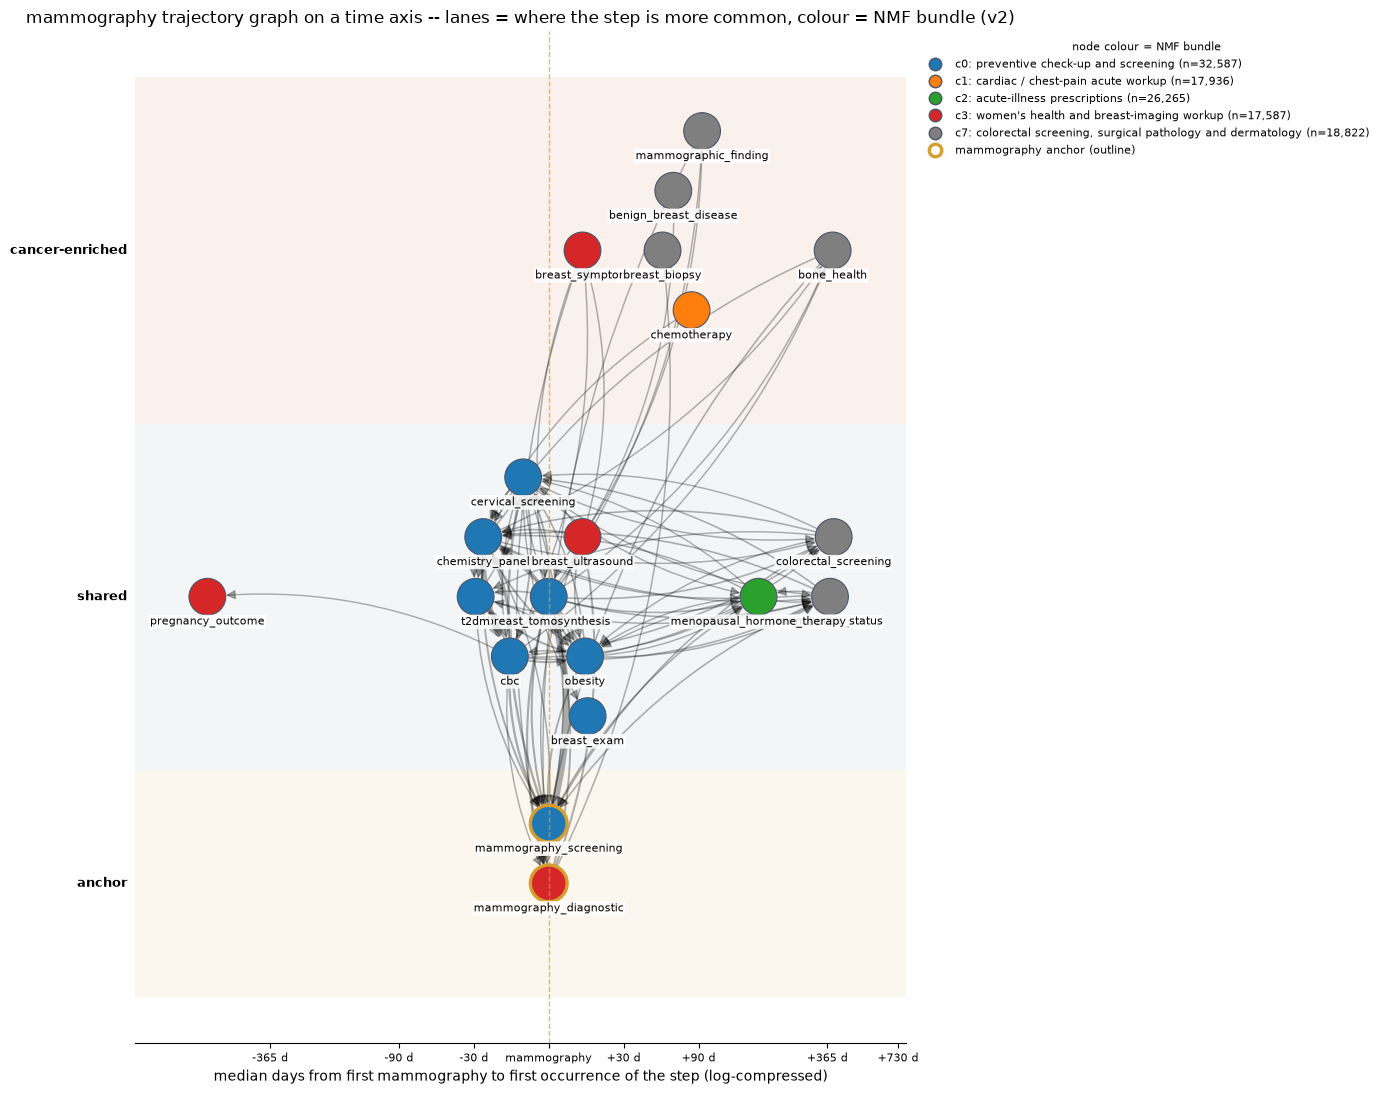

{'cancer-enriched': 6, 'shared': 12, 'anchor': 2} nodes per lane; 0 without timing

steps by bundle:
  c0: preventive check-up and screening  ->  breast_exam, breast_tomosynthesis, cbc, cervical_screening, chemistry_panel, mammography_screening, obesity, t2dm
  c1: cardiac / chest-pain acute workup  ->  chemotherapy
  c2: acute-illness prescriptions  ->  menopausal_hormone_therapy
  c3: women's health and breast-imaging workup  ->  breast_symptom, breast_ultrasound, mammography_diagnostic, pregnancy_outcome
  c7: colorectal screening, surgical pathology and dermatology  ->  benign_breast_disease, bone_health, breast_biopsy, colorectal_screening, mammographic_finding, menopause_status


In [27]:
MIN_N = 20                                                                      # fewer patients with both -> no timing, node parked at the right edge
SLOT, LABEL_IN = 1.0, 1.15                                                      # vertical stagger step (y units), room one label needs on the x axis (inches)
_nodes = set(G.nodes())
_first = {n: [] for n in _nodes}
for p in have:
    best = {}
    for g, d in zip(*gdated[p]):
        if g in _nodes and (g not in best or d < best[g]):
            best[g] = d
    for g, d in best.items():
        _first[g].append(d - a0[p])
med = {g: float(np.median(v)) for g, v in _first.items() if len(v) >= MIN_N}
for g in ANCHOR_GROUPS:
    if g in _nodes:
        med[g] = 0.0

LANES    = [l for l in ['cancer-enriched', 'shared', 'no-cancer-enriched', 'anchor'] if l in {lane_of[n] for n in _nodes}]
LANE_COL = {'cancer-enriched': '#c05621', 'no-cancer-enriched': '#2f855a', 'shared': '#718096', 'anchor': '#d69e2e'}

# node colour = the NMF bundle that owns the step: the component with the largest summed loading over the step's tokens (a codeset tag at group level)
tok_of  = events.loc[events.group.notna(), ['group', 'tag']].drop_duplicates().groupby('group').tag.agg(set)
def bundle_of(g):
    toks = sorted(tok_of.get(g, set()) & set(H.columns))
    return int(H[toks].sum(axis=1).to_numpy().argmax()) if toks else None
owner   = {n: bundle_of(n) for n in _nodes}
_cmap   = plt.get_cmap('tab10' if K <= 10 else 'tab20')
BUN_COL = {c: _cmap(c % _cmap.N) for c in range(K)}
NO_BUN  = '#cbd5e0'
short   = lambda c: re.sub(r' \(.*$', '', COMP[c])               # "c3: women's health ... (gyn exam, ...)" -> "c3: women's health ..."
tf = lambda d: np.sign(d) * np.log1p(np.abs(d) / 30)                            # days -> compressed axis, 0 stays 0
xs = {g: tf(m) for g, m in med.items() if g in _nodes}
x_park = (max(xs.values()) if xs else 0) + 1.4
_all_x = list(xs.values()) + ([x_park] if any(n not in xs for n in _nodes) else [])
MIN_DX = LABEL_IN * (max(_all_x) - min(_all_x) + 1) / 12.0                      # x units that fit one label on a 14 in wide figure
order  = [0] + [s * k for k in range(1, 13) for s in (1, -1)]
slot_of, lane_k = {}, {}
for l in LANES:
    members = sorted((n for n in _nodes if lane_of[n] == l), key=lambda n: (xs.get(n, x_park), n))
    last = {}                                                                   # slot -> x of the last node placed there
    for n in members:
        x = xs.get(n, x_park)
        k = next(k for k in order if x - last.get(k, -1e9) >= MIN_DX)
        last[k] = x; slot_of[n] = (l, k, x)
    lane_k[l] = max((abs(k) for (ll, k, _) in slot_of.values() if ll == l), default=0)
heights = {l: 2 * lane_k[l] * SLOT + 1.8 for l in LANES}                        # a lane is as tall as its stagger needs
centers, y_top = {}, 0.0
for l in LANES:
    centers[l] = y_top - heights[l] / 2; y_top -= heights[l]
pos_t = {n: (x, centers[l] + k * SLOT) for n, (l, k, x) in slot_of.items()}

fig, ax = plt.subplots(figsize=(14, max(5, 0.6 * (-y_top) + 1.8)))
for l in LANES:
    ax.axhspan(centers[l] - heights[l] / 2, centers[l] + heights[l] / 2, color=LANE_COL[l], alpha=.08, lw=0)
    ax.text(-0.01, centers[l], l, transform=ax.get_yaxis_transform(), ha='right', va='center', fontsize=9, fontweight='bold')
w = np.array([G[u][v]['weight'] for u, v in G.edges()], dtype=float)
nx.draw_networkx_edges(G, pos_t, ax=ax, width=1 + 4 * w / w.max(), alpha=.3, arrowsize=14, node_size=700, connectionstyle='arc3,rad=0.15')
nx.draw_networkx_nodes(G, pos_t, ax=ax, node_size=700, node_color=[NO_BUN if owner[n] is None else BUN_COL[owner[n]] for n in G.nodes()],
                       edgecolors=[LANE_COL['anchor'] if lane_of[n] == 'anchor' else '#4a5568' for n in G.nodes()],
                       linewidths=[2.4 if lane_of[n] == 'anchor' else .8 for n in G.nodes()])
from matplotlib.lines import Line2D
_h = [Line2D([], [], marker='o', ls='', ms=9, mfc=BUN_COL[c], mec='#4a5568', label=f"{short(c)} (n={comp_n[c]:,})") for c in sorted({o for o in owner.values() if o is not None})]
if any(o is None for o in owner.values()):
    _h.append(Line2D([], [], marker='o', ls='', ms=9, mfc=NO_BUN, mec='#4a5568', label='not in the NMF (floor / ceiling)'))
_h.append(Line2D([], [], marker='o', ls='', ms=9, mfc='white', mec=LANE_COL['anchor'], mew=2.4, label='mammography anchor (outline)'))
ax.legend(handles=_h, title='node colour = NMF bundle', loc='upper left', bbox_to_anchor=(1.01, 1.0), fontsize=8, title_fontsize=8, frameon=False)
nx.draw_networkx_labels(G, {n: (x, y_ - 0.42) for n, (x, y_) in pos_t.items()}, ax=ax, font_size=8, bbox=dict(boxstyle='round,pad=0.12', fc='white', ec='none', alpha=.85))
ax.tick_params(axis='x', bottom=True, labelbottom=True)                         # networkx hides the ticks
tick_d = [-365, -90, -30, 0, 30, 90, 365, 730]
ax.set_xticks([tf(d) for d in tick_d]); ax.set_xticklabels([f"{d:+d} d" if d else 'mammography' for d in tick_d], fontsize=8)
ax.axvline(0, color='#d69e2e', lw=1, ls='--', alpha=.7)
if any(n not in xs for n in _nodes):
    ax.text(x_park, 0.3, f'timing n<{MIN_N}', ha='center', fontsize=8, color='#718096')
ax.set_yticks([]); ax.spines[['left', 'right', 'top']].set_visible(False)
ax.set_xlabel("median days from first mammography to first occurrence of the step (log-compressed)")
ax.set_title(f'mammography trajectory graph on a time axis -- lanes = where the step is more common, colour = NMF bundle ({VARIANT})')
plt.margins(x=.06); plt.tight_layout(); plt.show()
print({l: sum(1 for n in _nodes if lane_of[n] == l) for l in LANES}, "nodes per lane;", sum(1 for n in _nodes if n not in xs), "without timing")
by_bundle = collections.defaultdict(list)
for n, o in owner.items():
    by_bundle[o].append(n)
print("\nsteps by bundle:")
for o in sorted(by_bundle, key=lambda x: (x is None, x)):
    print(f"  {'(not in the NMF)' if o is None else short(o)}  ->  {', '.join(sorted(by_bundle[o]))}")

## 6 · Final table — top motifs per group, with their verdicts

One block per NMF bundle. The label groups are not in the table: the label never enters the NMF, and the breast cancer / no cancer motifs stay in the sections above. Each block shows the top 5 entities, and the `TOPK` highest-lift scored ordered patterns with the position of each in the group's scored list,
its support in / out, re-tests found, held-out verdict, lift and final (hybrid) verdict. Under every entity: the median timing against the patient's first mammography. Entities are ranked by NMF loading in the bundle. Patterns that contain a cancer treatment / staging code start with `[proxy]`.
Column headers match the letrozole final table, so `pubmed-literature-check` can fill the last columns. Triage, literature and PMIDs are left empty.

In [28]:
from openpyxl.worksheet.datavalidation import DataValidation

TOPK, TOP_ENT = 3, 5
XLSX_FINAL = os.path.join(RES_DIR, f"final_table_{COHORT}_k{K}_{VARIANT}.xlsx")
ANCHOR_TOK = set(events.loc[eo.group_mask(events, ANCHOR), 'tag'])          # every concept token of the anchor group
ANCHOR_NAME = ANCHOR

_a0 = {}
def offset_text(key, members, t, min_n=20):
    """Median days from each member's first anchor step to their first occurrence of token t (negative = t came first), over members with both."""
    if key not in _a0:
        _a0[key] = np.array([min((patseqs[i].dpos[x][0] for x in ANCHOR_TOK if x in patseqs[i].dpos), default=np.nan) for i in members])
    td = np.array([patseqs[i].dpos[t][0] if t in patseqs[i].dpos else np.nan for i in members])
    g  = (td - _a0[key])[~np.isnan(td - _a0[key])]
    if len(g) < min_n:
        return f"\n    vs first {ANCHOR_NAME}: too few patients with both (n={len(g)})"
    m = int(np.median(g))
    when = "same day as" if m == 0 else f"{abs(m):,} d {'before' if m < 0 else 'after'}"
    return f"\n    median {when} first {ANCHOR_NAME} ({(g < 0).mean():.0%} of them before)"

HEAD = ['Group (bundle)', 'n (%)', 'Most frequently OMOP clinical entities found', 'Rank (by lift)', 'Typical order of care (condensed names, vocabulary + code)',
        "Position in the bundle's scored top patterns (by lift · by support)", 'Share of group with pattern', 'Share of everyone else with pattern', 'Re-tests found (of 5)',
        'Holds up on re-test?', 'Times as common (lift)', 'Final verdict', 'Triage suggestion (Manual RUW / Routine / Unclear)', 'Order shown by dates?',
        'Supported literature (Yes / Partly / None)', 'PMIDs']
BUNDLE_COLS = (1, 2, 3, 13)                                                   # merged down the rows of a block

BLOCKS = [(f"c{c} explained by " + re.sub(rf"^c{c}: ", "", COMP[c]), rows_comp.get(c), lab_k == c, c) for c in range(K)]
table = []
for bi, (bname, pool, mask, c) in enumerate(BLOCKS):
    members = np.flatnonzero(mask)
    pin  = pd.Series(np.asarray(Xs[members].mean(axis=0)).ravel(), index=nmf_cols)
    score = H.iloc[c]
    ents = "\n".join(f"{i}. {label(t)} ({pin[t]:.0%} of group){offset_text(bi, members, t)}" for i, t in enumerate(score.nlargest(TOP_ENT).index, 1))
    head = [bname, f"{len(members):,} ({len(members) / n_pat:.1%})", ents]
    pool = pool if pool is not None and len(pool) else None
    if pool is None:
        table.append((bi, head + ['', "no ordered pattern of >= 3 steps reached the support floor (or group too small to mine)"] + [''] * (len(HEAD) - 5)))
        continue
    pool = pool.assign(rk_lift=np.arange(1, len(pool) + 1), rk_sup=pool.sup_in.rank(ascending=False, method='min').astype(int))   # pool is lift-sorted
    for rk, (_, r) in enumerate(pool.head(TOPK).iterrows(), 1):
        holds = 'Yes' if r.splits_found >= 4 else 'Partly' if r.splits_found == 3 else 'No'
        row = (head if rk == 1 else ['', '', '']) + [rk, ('[proxy] ' if r.has_proxy else '') + pattern_text(r.pattern),
                f"{int(r.rk_lift)} of {len(pool)} by lift · {int(r.rk_sup)} of {len(pool)} by support", float(r.sup_in), float(r.sup_out), int(r.splits_found), holds,
                float(r.lift), r.hybrid_verdict.capitalize(), '', 'Same-day bundle' if r.same_day_bundle else 'Yes', '', '']
        table.append((bi, row))

FILL = {'Yes': 'D6F0DE', 'Partly': 'FBEFC9', 'No': 'F8D7D7', 'Solid': 'D6F0DE', 'Suggestive': 'FBEFC9', 'Unstable': 'F8D7D7', 'Same-day bundle': 'FBEFC9'}
F = lambda **kw: Font(name='Arial', size=10, **kw)
thin = Side(style='thin', color='D0D5DB')
wb = openpyxl.Workbook(); ws = wb.active; ws.title = f'{COHORT} k={K}'
ws.append(HEAD)
for j in range(1, len(HEAD) + 1):
    h = ws.cell(1, j); h.font = Font(name='Arial', size=10, bold=True, color='FFFFFF')
    h.fill = PatternFill('solid', fgColor='334E68'); h.alignment = Alignment(wrap_text=True, vertical='center', horizontal='center')
ws.row_dimensions[1].height = 44
for _, row in table:
    ws.append(row)
dv = DataValidation(type='list', formula1='"Yes,Partly,None"', allow_blank=True); ws.add_data_validation(dv)
LEFT = {1, 3, 5, 13}
for i in range(2, len(table) + 2):
    ws.row_dimensions[i].height = 64
    for j in range(1, len(HEAD) + 1):
        c_ = ws.cell(i, j); c_.font = F(bold=(j == 1)); c_.border = Border(bottom=thin)
        c_.alignment = Alignment(wrap_text=True, vertical='top', horizontal='left' if j in LEFT else 'center')
    for j in (7, 8): ws.cell(i, j).number_format = '0.0%'
    ws.cell(i, 11).number_format = '0.0'
    for j in (10, 12, 14):
        v = ws.cell(i, j).value
        if v in FILL: ws.cell(i, j).fill = PatternFill('solid', fgColor=FILL[v]); ws.cell(i, j).font = F(bold=True)
    dv.add(ws.cell(i, 15))
r0 = 2
for b, grp in itertools.groupby([b for b, _ in table]):                       # one merged block per group
    n = len(list(grp)); r1 = r0 + n - 1
    if n > 1:
        for j in BUNDLE_COLS: ws.merge_cells(start_row=r0, end_row=r1, start_column=j, end_column=j)
    r0 = r1 + 1
for j, w_ in enumerate([30, 22, 70, 8, 80, 22, 12, 13, 11, 11, 11, 12, 34, 14, 16, 16], 1):
    ws.column_dimensions[get_column_letter(j)].width = w_
ws.freeze_panes = 'B2'
notes = [
    "Notes",
    f"Source: {TAG}, NMF k={K} on {TOKEN_LEVEL}-level tokens, codesets {CODESETS_FILE}, {n_pat:,} patients, variant {VARIANT}. Groups are the NMF bundles c0, c1, ... "
    "n (%) = patients whose dominant component is the bundle. The breast cancer label never enters NMF or the mining.",
    f"Entities: top {TOP_ENT} OMOP concepts; ranked by NMF loading in the bundle. The % is the share of the group's patients with that code. "
    f"Under each entity, the median days from the patient's first {ANCHOR_NAME} step to the FIRST occurrence of that entity, over group patients who have both.",
    f"Patterns: the {TOPK} highest-lift scored ordered patterns of each group (ordered patterns of {M_['min_len']}-{M_['max_len']} steps, each present in >= {M_['rel_sup']:.0%} of the group). '[proxy]' = the pattern contains a cancer treatment / staging code (LABEL_PROXY_TAGS).",
    "Position among the group's scored patterns: candidates are the group's most frequent ordered patterns that pass the support floor, scored for lift; the place by lift (1 = most specific) and by support, out of the N patterns scored.",
    f"Times as common = (share inside + 0.01) / (share outside + 0.01). Outside = random sample of {M_['n_out']:,} patients from the other groups.",
    f"Re-tests: each group split in half at random, {len(ST_['split_seeds'])} times; patterns found on one half and checked on the other. Yes = found in {ST_['min_splits_ok']}-{len(ST_['split_seeds'])}, Partly = {ST_['min_splits_ok'] - 1}, No = fewer.",
    f"Final verdict = the hybrid verdict: Solid = re-found in >= {ST_['min_splits_ok']} of {len(ST_['split_seeds'])} re-tests with lift range low >= {S_['min_lift']}, downgraded to Suggestive when the family held-out pass rate lower bound is below {HO_['min_rate_lo']:.0%} ({HO_['n_seeds']} splits x 2 directions); Suggestive = found in {ST_['min_splits_ok'] - 1}; Unstable otherwise.",
    f"Order shown by dates? 'Same-day bundle' = with every step on a strictly later day, support falls below {HO_['same_day_ratio']:.0%} of its table value: the steps mostly occur together on one day, so the order is a tie-break, not evidence.",
    "Triage suggestion, Supported literature (Yes / Partly / None, drop-down) and PMIDs are left empty for the review.",
    "In-situ note: patients with in-situ disease only (DCIS / LCIS) are kept (DROP_INSITU_ONLY = False) and count as no breast cancer in the label. They are pre-cancer with some risk and need manual review, so read a bundle that holds them (see the in_situ row of the codeset loadings) with that in mind when writing its name, triage and literature.",
    "'×N' = the same concept appears N times in a row. '[code group]' = a curated group of several codes.",
]
for k_, t in enumerate(notes):
    ws.cell(len(table) + 3 + k_, 1, t).font = F(bold=(k_ == 0))
wb.save(XLSX_FINAL)
print(f"wrote {os.path.abspath(XLSX_FINAL)}  ({len(BLOCKS)} blocks, {len(table)} rows)")
pd.DataFrame([r for _, r in table], columns=HEAD).iloc[:, :12]

wrote /Users/esteban.correaagudelo/codeprojects/ethos_foundation_llm/nb/repr_learn_mammography/outputs/final_table_mammography_k8_v2.xlsx  (8 blocks, 24 rows)


,Group (bundle),n (%),Most frequently OMOP clinical entities found,Rank (by lift),"Typical order of care (condensed names, vocabulary + code)",Position in the bundle's scored top patterns (by lift · by support),Share of group with pattern,Share of everyone else with pattern,Re-tests found (of 5),Holds up on re-test?,Times as common (lift),Final verdict
0,"c0 explained by preventive check-up and screening (screening mammography, tomosynthesis, preventive visit, lipid pan...","32,587 (22.9%)",1. mammography screening [code group] (98% of group)\n median same day as first mammography (0% of them before)\n...,1,Periodic comprehensive preventive… [CPT4 99396] → General examination of patient [SNOMED 162673000] → Lipid panel [C...,1 of 100 by lift · 15 of 100 by support,0.545,0.340,0,No,1.6,Unstable
1,,,,2,Periodic comprehensive preventive… [CPT4 99396] → General examination of patient [SNOMED 162673000] → Venipuncture f...,2 of 100 by lift · 57 of 100 by support,0.468,0.297,0,No,1.6,Unstable
2,,,,3,General examination of patient [SNOMED 162673000] → Lipid panel [CPT4 80061] → mammography screening [code group],3 of 100 by lift · 28 of 100 by support,0.504,0.341,0,No,1.5,Unstable
3,"c1 explained by cardiac / chest-pain acute workup (ECG, troponin, chest X-ray, dyspnea, lipase, headache; also chemo...","17,936 (12.6%)","1. Electrocardiogram, routine ECG with… [CPT4 93010] (72% of group)\n median 75 d after first mammography (45% of...",1,"Electrocardiogram, routine ECG with… [CPT4 93005] → chemistry panel [code group] → cbc [code group]",1 of 100 by lift · 63 of 100 by support,0.660,0.123,5,Yes,5.0,Solid
4,,,,2,chemistry panel [code group] ×4,2 of 100 by lift · 86 of 100 by support,0.647,0.219,5,Yes,2.9,Solid
5,,,,3,cbc [code group] → chemistry panel [code group] → cbc [code group] → chemistry panel [code group],3 of 100 by lift · 60 of 100 by support,0.664,0.229,5,Yes,2.8,Solid
6,"c2 explained by acute-illness prescriptions (steroids, antibiotics for respiratory and urinary infection, antifungal...","26,265 (18.4%)",1. {21 (methylprednisolone 4 MG Oral… [RxNorm 762675] (57% of group)\n median 105 d before first mammography (54%...,1,prednisone 20 MG Oral Tablet [RxNorm 312615] → mammography screening [code group] → breast tomosynthesis [code group],1 of 100 by lift · 11 of 100 by support,0.330,0.084,5,Yes,3.6,Solid
7,,,,2,mammography screening [code group] → breast tomosynthesis [code group] → prednisone 20 MG Oral Tablet [RxNorm 312615],2 of 100 by lift · 30 of 100 by support,0.262,0.076,5,Yes,3.2,Solid
8,,,,3,{21 (methylprednisolone 4 MG Oral… [RxNorm 762675] → mammography screening [code group] → breast tomosynthesis [code...,3 of 100 by lift · 6 of 100 by support,0.390,0.119,5,Yes,3.1,Solid
9,"c3 explained by women's health and breast-imaging workup (gyn exam, cervical screening, STI nucleic-acid and urine t...","17,587 (12.3%)",1. Infectious agent detection by nucleic… [CPT4 87491] (69% of group)\n median 156 d before first mammography (65...,1,Infectious agent detection by nucleic… [CPT4 87491] → Infectious agent detection by nucleic… [CPT4 87591] → cervical...,1 of 100 by lift · 70 of 100 by support,0.432,0.049,5,Yes,7.5,Solid


## 7 · Member table — which concepts sit behind each token
One row per OMOP concept with the token it carries (`outputs/token_members_k{K}_{TAG}.csv`). At group level a token is a codeset tag with many concepts; a predicate or an engine entity is then `concept_id IN (...)` over its rows.
Includes (a) every concept seen in the cohort's events after the filters (`n_events > 0`) and (b) every codeset member never seen (`n_events = 0`, `in_cohort` False): label concepts removed by F2 (`in_label` True), concepts below the F7 floor, or concepts absent from the cohort. Run it after the final table (needs `K`, `H`, `rows_lab`, `rows_comp`).


In [29]:
# Member table: one row per OMOP concept with the token it carries. At TOKEN_LEVEL='group' a token is a codeset tag and has many rows; at 'concept' it has one.
import collections
MEMBERS_CSV = os.path.join(RES_DIR, f"token_members_k{K}_{TAG}.csv")
META  = [c for c in ('concept_name', 'vocabulary_id', 'concept_code', 'concept_class_id', 'domain') if c in events.columns]

first = events.drop_duplicates('concept_id').set_index('concept_id')
cnt   = events.groupby('concept_id').person_id.agg(n_events='size', n_patients='nunique')
seen  = first[['tag'] + META].rename(columns={'tag': 'token'}).join(cnt)
seen['groups'] = first['groups'].astype(str).where(first['groups'].notna(), '')            # every codeset the concept is in, '|'-joined

lookup, members = {}, {}                                                                   # same rule as eo.tag_events: first tag in yaml order wins
for tag, ids in codesets.items():
    for cid in ids:
        lookup.setdefault(cid, tag); members.setdefault(cid, []).append(tag)
cmeta  = concept.drop_duplicates('concept_id').set_index('concept_id').rename(columns={'domain_id': 'domain'})
unseen = cmeta.reindex([c for c in members if c not in seen.index]).reindex(columns=META)
unseen['token']      = unseen.index.map(lookup) if TOKEN_LEVEL == 'group' else ''         # at concept level the token of an unseen concept does not exist
unseen['groups']     = unseen.index.map(lambda c: '|'.join(members[c]))
unseen['n_events']   = 0
unseen['n_patients'] = 0

member_tbl = pd.concat([seen, unseen]).rename_axis('concept_id').reset_index()
assert member_tbl.concept_id.is_unique, "a concept carries more than one token"
member_tbl['in_cohort']        = member_tbl.n_events > 0
member_tbl['in_label']         = member_tbl.concept_id.isin(LABEL_CONCEPTS)                # removed from the features by F2
member_tbl['token_n_concepts'] = member_tbl.groupby('token').concept_id.transform('size').where(member_tbl.token != '')   # all members, seen or not
member_tbl['token_n_patients'] = member_tbl.token.map(events.groupby('tag').person_id.nunique()).astype('Int64')           # patients with ANY member of the token
member_tbl['in_nmf']           = member_tbl.token.isin(H.columns)
member_tbl['nmf_owner']        = member_tbl.token.map(H.idxmax(axis=0)).astype('Int64')                                    # component with the largest loading (blank = not in the NMF)
member_tbl['owner_share']      = member_tbl.token.map(H.max(axis=0) / H.sum(axis=0)).round(3)
_in_motifs = collections.Counter(t for d in list(rows_comp.values()) + list(rows_lab.values()) if len(d) for p in d.pattern for t in set(p.split(' -> ')))
member_tbl['n_motifs']         = member_tbl.token.map(lambda t: _in_motifs.get(t, 0))
member_tbl = member_tbl.sort_values(['token_n_patients', 'token', 'n_patients'], ascending=[False, True, False], na_position='last')
member_tbl = member_tbl[['token', 'concept_id'] + META + ['n_events', 'n_patients', 'groups', 'in_cohort', 'in_label', 'token_n_concepts', 'token_n_patients', 'in_nmf', 'nmf_owner', 'owner_share', 'n_motifs']]
member_tbl.to_csv(MEMBERS_CSV, index=False)

multi = member_tbl[member_tbl.token_n_concepts > 1]
print(f"wrote {os.path.abspath(MEMBERS_CSV)}: {len(member_tbl):,} concepts | {multi.token.nunique():,} group tokens ({len(multi):,} concepts) | "
      f"{int((~member_tbl.in_cohort).sum()):,} codeset members absent from the cohort after the filters")
top5 = {t for c in range(K) for t in H.iloc[c].nlargest(5).index}                           # group tokens that define a bundle, with their members
show = (multi[multi.token.isin(top5)].groupby('token', sort=False)
             .agg(owner=('nmf_owner', 'first'), members=('concept_id', 'size'), seen=('in_cohort', 'sum'), patients=('token_n_patients', 'first')))
print("\ngroup tokens among the top-5 loadings of a bundle:")
print(show.to_string())
member_tbl.head(8)


wrote /Users/esteban.correaagudelo/codeprojects/ethos_foundation_llm/nb/repr_learn_mammography/outputs/token_members_k8_mammography_v2.csv: 26,246 concepts | 41 group tokens (457 concepts) | 14 codeset members absent from the cohort after the filters

group tokens among the top-5 loadings of a bundle:
                       owner  members  seen  patients
token                                                
breast_tomosynthesis       0        4     4    133602
mammography_screening      0        3     3    130398
cervical_screening         0       40    40     77753
colorectal_screening       7       24    24     46629


,token,concept_id,concept_name,vocabulary_id,concept_code,concept_class_id,domain,n_events,n_patients,groups,in_cohort,in_label,token_n_concepts,token_n_patients,in_nmf,nmf_owner,owner_share,n_motifs
9,breast_tomosynthesis,46257421,"Screening digital breast tomosynthesis, bilateral (List separately in addition to code for primary procedure)",CPT4,77063,CPT4,Procedure,465488,122002,breast_tomosynthesis,True,False,4,133602,True,0,0.416,381
97,breast_tomosynthesis,42872575,Digital breast tomosynthesis,SNOMED,450566007,Procedure,Procedure,39924,20274,breast_tomosynthesis,True,False,4,133602,True,0,0.416,381
750,breast_tomosynthesis,37109864,Digital tomosynthesis of bilateral breasts,SNOMED,723780005,Procedure,Procedure,34520,17705,breast_tomosynthesis,True,False,4,133602,True,0,0.416,381
727,breast_tomosynthesis,46257687,Diagnostic digital breast tomosynthesis; unilateral,CPT4,77061,CPT4,Procedure,30518,15729,breast_tomosynthesis,True,False,4,133602,True,0,0.416,381
8,mammography_screening,42627987,"Screening mammography, bilateral (2-view study of each breast), including computer-aided detection (CAD) when performed",CPT4,77067,CPT4,Procedure,515069,130390,mammography_screening|mammography,True,False,3,130398,True,0,0.483,338
12077,mammography_screening,36713187,Screening mammography of bilateral breasts,SNOMED,384151000119104,Procedure,Procedure,50,37,mammography_screening|mammography,True,False,3,130398,True,0,0.483,338
23944,mammography_screening,4077697,Screening mammography,SNOMED,24623002,Procedure,Procedure,1,1,mammography_screening|mammography,True,False,3,130398,True,0,0.483,338
16,venipuncture_for_blo__procedure__4102442,4102442,Venipuncture for blood test,SNOMED,28520004,Procedure,Procedure,729863,105715,,True,False,1,105715,True,0,0.455,441
